# Лабораторная работа: математический анализ и матричное исчисление


**Выполненная работа:** все задания 1.1–10.1 решены, 25 ячеек кода выполнены сверху вниз, выводы и графики сохранены. Исходный шаблон оставлен рядом без изменений. Для повторного запуска нужны NumPy, Matplotlib и Jupyter; рабочая папка — папка ноутбука. Центральные разности во всём решении используют точки x±h/2 и делитель h. Ссылки на пособие и две иллюстрации исправлены на существующую соседнюю папку «Линейная алгебра — Лабораторная работа».


## Назначение работы

Эта лабораторная работа учит читать сложные формулы как точные инструкции над числами, векторами, матрицами и тензорами. Мы начнём с сумм и индексов, перейдём к производной обычной функции, затем последовательно построим градиент, производную по направлению, полную производную, якобиан, произведения с якобианом, гессиан и матричные градиенты. В конце все операторы соединятся в одной составной параметрической функции, для которой будут вручную выведены производные, выполнена численная проверка и проведена оптимизация.

Работа образует одну непрерывную канву. Каждый следующий объект отвечает на ограничение предыдущего: одной производной недостаточно для функции многих переменных; одного градиента недостаточно для векторного выхода; полный якобиан не всегда следует строить явно; первая производная показывает направление изменения, а гессиан — изменение самого градиента и локальную кривизну.

Единственный источник теории, формул и соглашений об обозначениях — пособие [«Линейная алгебра»](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf). Из «Высшей математики. Практикума» (внешний источник условия; в папке отсутствует) перенесены только несколько начальных условий для ручного решения. Остальные аналитические и вычислительные задания специально составлены для этой работы.


## Как выполнять работу

Этапы помечены способом работы:

- **[Бумага]** — вывести результат аналитически без NumPy;
- **[Markdown]** — оформить рассуждение и формулы в Markdown-ячейке;
- **[Python]** — проверить вывод или исследовать численное поведение;
- **[Интерпретация]** — объяснить тип, размерность и практический смысл результата.

Сначала выполняйте пункт **[Бумага]**, затем переносите решение в ноутбук и только после этого запускайте проверочный код. Численное совпадение не заменяет вывода: программа проверяет формулу в выбранной точке, но не доказывает её для всех допустимых аргументов.

Для каждой сложной формулы придерживайтесь четырёх вопросов:

1. Каков тип входа: скаляр, вектор, матрица или тензор?
2. Какие индексы свободны, а по каким выполняется суммирование?
3. Какова размерность результата?
4. Можно ли вычислить нужное произведение, не формируя большую производную целиком?


### Единая траектория

1. Сумма по индексам превращается в матричное или тензорное произведение.
2. Предел отношения приращений определяет локальную скорость изменения.
3. Частные производные собираются в градиент.
4. Градиент задаёт изменение в выбранном направлении.
5. Производные векторной функции собираются в якобиан.
6. Цепное правило превращается в произведение якобианов или векторно-якобианное произведение.
7. Вторые частные производные образуют гессиан и описывают кривизну.
8. Индексные выводы сворачиваются в компактные матричные градиенты.
9. Градиенты составной функции проверяются конечными разностями.
10. Проверенные градиенты используются для уменьшения целевой функции.


## Соглашения и общий пакет данных

Градиент скалярной функции $f:\mathbb R^n\to\mathbb R$ считаем вектором-столбцом. Для отображения $\mathbf f:\mathbb R^n\to\mathbb R^m$ используем якобиан, строки которого соответствуют компонентам выхода:

$$
\mathbf J_{\mathbf f}(\mathbf x)
=\frac{\partial\mathbf f}{\partial\mathbf x^{\mathsf T}}
\in\mathbb R^{m\times n}.
$$

Сквозной вычислительный пример использует пакет из $N=4$ наблюдений, $D=3$ входных координат и $K=2$ выходных координат:

$$
\mathbf X=
\begin{pmatrix}
1&0&-1\\
0&1&1\\
1&1&0\\
-1&2&1
\end{pmatrix}\in\mathbb R^{4\times3},
\qquad
\mathbf Y=
\begin{pmatrix}
0.2&0.8\\
0.7&0.1\\
0.6&0.4\\
0.1&0.9
\end{pmatrix}\in\mathbb R^{4\times2}.
$$

Начальные параметры:

$$
\mathbf W_0=
\begin{pmatrix}
0.2&-0.3\\
0.4&0.1\\
-0.5&0.2
\end{pmatrix}\in\mathbb R^{3\times2},
\qquad
\mathbf b_0=
\begin{pmatrix}0.1\\-0.2\end{pmatrix},
\qquad \lambda=0.05.
$$

В конце работы вычисляется композиция

$$
\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T},
\qquad
\mathbf H=\sigma(\mathbf Z),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}},
$$

и скалярная целевая функция

$$
\mathcal L(\mathbf W,\mathbf b)
=\frac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2
+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2.
$$

Пока не дифференцируйте эту запись: к ней будем возвращаться после освоения каждого необходимого оператора.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

X_data = np.array([
    [1, 0, -1],
    [0, 1, 1],
    [1, 1, 0],
    [-1, 2, 1],
], dtype=float)

Y_data = np.array([
    [0.2, 0.8],
    [0.7, 0.1],
    [0.6, 0.4],
    [0.1, 0.9],
], dtype=float)

W_initial = np.array([
    [0.2, -0.3],
    [0.4, 0.1],
    [-0.5, 0.2],
], dtype=float)

b_initial = np.array([0.1, -0.2], dtype=float)
regularization = 0.05

def sigmoid(z):
    """Устойчивая поэлементная сигмоида."""
    z_safe = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_safe))

print("X:", X_data.shape, "Y:", Y_data.shape)
print("W:", W_initial.shape, "b:", b_initial.shape)
print("lambda =", regularization)


X: (4, 3) Y: (4, 2)
W: (3, 2) b: (2,)
lambda = 0.05


## 1. Суммы, индексы и матричная запись


### Короткая теория

Если $\mathbf A\in\mathbb R^{m\times n}$ и $\mathbf B\in\mathbb R^{n\times p}$, то

$$
\mathbf C=\mathbf A\mathbf B\in\mathbb R^{m\times p},
\qquad
C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}.
$$

Индексы $i$ и $j$ свободны: они остаются у результата. Индекс $k$ суммируемый, или фиктивный: он пробегает допустимые значения и исчезает после суммирования. В нотации Эйнштейна знак суммы можно опустить, если правило суммирования однозначно. См. [матричное произведение, с. 15–18](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D15) и [суммирование Эйнштейна, с. 20](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D20).

![Умножение матриц](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/assets/figures/figure-05.png)

*Каждый элемент произведения получается свёрткой строки первой матрицы со столбцом второй.*


### Задание 1.1. От суммы к матрице

Даны

$$
\mathbf A=
\begin{pmatrix}1&2&-1\\0&3&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&1\\1&-1\\0&2\end{pmatrix}.
$$

- **[Бумага]** Укажите размеры $\mathbf A$, $\mathbf B$ и $\mathbf C=\mathbf A\mathbf B$. Распишите каждый $C_{ij}$ отдельной суммой.
- **[Markdown]** Подпишите свободные и суммируемый индексы в $C_{ij}=\sum_kA_{ik}B_{kj}$.
- **[Python]** Сравните ручной результат с `A @ B` и с тройным циклом по $i,j,k$.
- **[Интерпретация]** Объясните, почему индекс $k$ отсутствует в обозначении $C_{ij}$ и почему поменять местами $j$ и $k$ нельзя.


#### Решение и интерпретация

$A\in\mathbb R^{2\times3}$, $B\in\mathbb R^{3\times2}$, $C=AB\in\mathbb R^{2\times2}$.
$$C_{11}=1\cdot2+2\cdot1+(-1)\cdot0=4,\quad C_{12}=1\cdot1+2(-1)+(-1)\cdot2=-3,$$
$$C_{21}=0\cdot2+3\cdot1+1\cdot0=3,\quad C_{22}=0\cdot1+3(-1)+1\cdot2=-1.$$
Таким образом, $C=\begin{pmatrix}4&-3\\3&-1\end{pmatrix}$. В $C_{ij}=\sum_{k=1}^3 A_{ik}B_{kj}$ индексы $i,j$ свободны (1…2), а $k$ суммируется (1…3) и исчезает. Переименовать фиктивный индекс можно согласованно во всей сумме, но просто заменить его свободным j нельзя: изменятся оси, пределы и смысл свёртки. Ручная матрица, `@` и тройной цикл совпадают.


In [2]:
A = np.array([[1, 2, -1], [0, 3, 1]], dtype=float)
B = np.array([[2, 1], [1, -1], [0, 2]], dtype=float)

C_manual = np.array([[4, -3], [3, -1]])
C_matmul = A @ B
C_loops = np.zeros((A.shape[0], B.shape[1]))
for i in range(A.shape[0]):
    for j in range(B.shape[1]):
        for k in range(A.shape[1]):
            C_loops[i, j] += A[i, k] * B[k, j]
print(C_manual, C_matmul, C_loops, sep="\n")
assert np.allclose(C_manual, C_matmul) and np.allclose(C_loops, C_matmul)


[[ 4 -3]
 [ 3 -1]]
[[ 4. -3.]
 [ 3. -1.]]
[[ 4. -3.]
 [ 3. -1.]]


### Задание 1.2. Три индекса и две свёртки

Рассмотрим тензор $S_{ntk}$ и матрицы $W_{kd}$, $V_{dc}$:

$$
S=
\left[
\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix},
\begin{pmatrix}0&1&0\\0&0&1\end{pmatrix}
\right],
$$

$$
\mathbf W=
\begin{pmatrix}1&0\\0&2\\1&-1\end{pmatrix},
\qquad
\mathbf V=
\begin{pmatrix}1&-1\\2&1\end{pmatrix}.
$$

Определим

$$
L_{nc}=\sum_{t=1}^{2}\sum_{k=1}^{3}\sum_{d=1}^{2}
S_{ntk}W_{kd}V_{dc}.
$$

- **[Бумага]** Укажите размер каждого объекта и результата. Для $L_{11}$ выпишите все слагаемые до удаления нулей.
- **[Markdown]** Объясните, почему $n,c$ свободны, а $t,k,d$ суммируются. Запишите то же выражение в нотации Эйнштейна.
- **[Интерпретация]** Опишите вычисление как последовательность двух более простых преобразований с промежуточной матрицей $E_{nd}$.


#### Решение и интерпретация

Формы: $S:2\times2\times3$, $W:3\times2$, $V:2\times2$, $E:2\times2$, $L:2\times2$.
Для $L_{11}$ имеется $2\cdot3\cdot2=12$ слагаемых (порядок t, k, d):
$$\begin{aligned}L_{11}={}&1\cdot1\cdot1+1\cdot0\cdot2+0\cdot0\cdot1+0\cdot2\cdot2+0\cdot1\cdot1+0\cdot(-1)\cdot2\\
&+0\cdot1\cdot1+0\cdot0\cdot2+1\cdot0\cdot1+1\cdot2\cdot2+0\cdot1\cdot1+0\cdot(-1)\cdot2=5.\end{aligned}$$
Промежуточный объект $E_{nd}=\sum_{t,k}S_{ntk}W_{kd}$ агрегирует t и преобразует признаки k в d; затем $L_{nc}=\sum_d E_{nd}V_{dc}$ преобразует d в c.
$$E=\begin{pmatrix}1&2\\1&1\end{pmatrix},\quad L=EV=\begin{pmatrix}5&1\\3&0\end{pmatrix}.$$
Индексы n,c сохраняются, t,k,d исчезают. В расширенной нотации Эйнштейна с явным выходом: $S_{ntk}W_{kd}V_{dc}\to L_{nc}$, суммируются все индексы вне выхода. В строгой парной конвенции t встречается лишь один раз, поэтому следует ввести $q_t=1$ и писать $L_{nc}=q_t S_{ntk}W_{kd}V_{dc}$: тогда каждый фиктивный индекс повторён дважды.


In [3]:
S_tensor = np.array([
    [[1, 0, 0], [0, 1, 0]],
    [[0, 1, 0], [0, 0, 1]],
], dtype=float)
W_tensor = np.array([[1, 0], [0, 2], [1, -1]], dtype=float)
V_tensor = np.array([[1, -1], [2, 1]], dtype=float)

print("S:", S_tensor.shape, "W:", W_tensor.shape, "V:", V_tensor.shape)
expected_E_shape = (2, 2)
expected_L_shape = (2, 2)
print("Ожидаемые формы E, L:", expected_E_shape, expected_L_shape)


S: (2, 2, 3) W: (3, 2) V: (2, 2)
Ожидаемые формы E, L: (2, 2) (2, 2)


### Задание 1.3. Циклы, матрицы и `einsum`

- **[Python]** Вычислите $L_{nc}$ четырьмя способами: вложенными циклами, через промежуточную матрицу $E$, одним `np.einsum` и двумя последовательными `np.einsum`.
- **[Markdown]** Запишите строки индексов для `einsum` и сопоставьте их математическим индексам.
- **[Интерпретация]** Объясните, почему совпадение четырёх реализаций является хорошей проверкой индексов, но не заменяет проверки размерностей до запуска.


#### Решение и интерпретация

Одношаговая запись: `np.einsum("ntk,kd,dc->nc", S, W, V)`. Индексы слева обозначают оси входов, справа — сохраняемые оси n,c; отсутствующие справа t,k,d суммируются. В NumPy при явном выходе допускается суммирование индекса t, встречающегося только в одном входе.
Двухшаговая запись: `"ntk,kd->nd"`, затем `"nd,dc->nc"`. Эквивалентная матричная запись: `E=S.sum(axis=1) @ W`, `L=E @ V`. Все четыре реализации ниже дают $\begin{pmatrix}5&1\\3&0\end{pmatrix}$. Это проверяет согласованность реализаций на данных, но одинаковая ошибка в смысле осей может остаться даже при совпадении чисел; размерности и значения индексов нужно установить заранее.


In [4]:
L_loops = np.zeros(expected_L_shape)
for n in range(2):
    for c in range(2):
        for t in range(2):
            for k in range(3):
                for d in range(2):
                    L_loops[n,c] += S_tensor[n,t,k]*W_tensor[k,d]*V_tensor[d,c]
E_matrix = S_tensor.sum(axis=1) @ W_tensor
L_matrix = E_matrix @ V_tensor
L_einsum_once = np.einsum("ntk,kd,dc->nc", S_tensor, W_tensor, V_tensor)
L_einsum_twice = np.einsum("nd,dc->nc", np.einsum("ntk,kd->nd", S_tensor, W_tensor), V_tensor)
print("E =", E_matrix, sep="\n")
for label, value in [("циклы", L_loops), ("матрицы", L_matrix), ("einsum один", L_einsum_once), ("einsum два", L_einsum_twice)]:
    print(label, value, sep="\n")
    assert value.shape == expected_L_shape and np.allclose(value, [[5,1],[3,0]])


E =
[[1. 2.]
 [1. 1.]]
циклы
[[5. 1.]
 [3. 0.]]
матрицы
[[5. 1.]
 [3. 0.]]
einsum один
[[5. 1.]
 [3. 0.]]
einsum два
[[5. 1.]
 [3. 0.]]


## 2. Функции одной переменной


### Короткая теория

Производная функции $f:\mathbb R\to\mathbb R$ в точке $x$ определяется пределом

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

Для малого $h$ функция локально заменяется касательной:

$$
f(x+h)\approx f(x)+f'(x)h.
$$

Прямую, центральную и обратную конечные разности, а также причину потери точности при слишком малом $h$ см. в [теории, с. 39–40](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D39). Правила для степенной, экспоненциальной, логарифмической и сложной функций приведены на [с. 42](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D42).


### Задание 2.1. Производная как предел и как численный оператор

Для $f(x)=e^x$ и $x_0=1$ рассмотрите

$$
D_+(h)=\frac{f(x_0+h)-f(x_0)}{h},
\quad
D_0(h)=\frac{f(x_0+h/2)-f(x_0-h/2)}{h},
\quad
D_-(h)=\frac{f(x_0)-f(x_0-h)}{h}.
$$

- **[Бумага]** Найдите точную производную и уравнение касательной в $x_0$.
- **[Markdown]** Объясните, почему все три выражения стремятся к одному числу, но при конечном $h$ имеют разные ошибки.
- **[Python]** Для $h=10^{-1},\ldots,10^{-16}$ вычислите абсолютные ошибки и постройте логарифмический график. Отдельно покажите функцию и касательную около $x_0$.
- **[Интерпретация]** Найдите область лучших $h$ и объясните рост ошибки при чрезмерно малом шаге вычитанием близких чисел.


#### Решение и интерпретация

$f'(x)=e^x$, поэтому $f'(1)=e$ и касательная $y=e+e(x-1)=ex$.
Из разложения $e^h=1+h+h^2/2+h^3/6+\cdots$:
$$D_+=e(1+h/2+h^2/6+\cdots),\quad D_-=e(1-h/2+h^2/6-\cdots),$$
$$D_0=e\frac{2\sinh(h/2)}h=e(1+h^2/24+O(h^4)).$$
У односторонних разностей ошибка аппроксимации $O(h)$, у центральной — $O(h^2)$; все сходятся к e в точной арифметике. В float64 добавляется ошибка порядка $\epsilon/h$ из-за вычитания близких чисел. Поэтому оптимальные шаги ожидаются примерно около $10^{-8}$ для односторонних и $10^{-5}$ для центральной разности, а при $10^{-16}$ соседние аргументы могут округлиться к одному числу. Фактические минимумы для исследуемой сетки и таблица ошибок приведены ниже: отдельный лучший шаг зависит от округления. График касательной показывает совпадение значения и наклона в x=1, но не всей экспоненты.


**Результат запуска:** минимум ошибок односторонних разностей на данной сетке достигнут при h=10⁻⁸ (6.603·10⁻⁹), центральной — при h=10⁻⁵ (5.859·10⁻¹¹); h=10⁻⁶ практически столь же точен. При h=10⁻¹⁶ все три приближения дают ноль, а ошибка равна e.


h | ошибки: прямая, центральная, обратная
1e-01 1.405601e-01 1.132759e-03 1.314947e-01
1e-02 1.363683e-02 1.132619e-05 1.354622e-02
1e-03 1.359594e-03 1.132614e-07 1.358688e-03
1e-04 1.359186e-04 1.133283e-09 1.359096e-04
1e-05 1.359150e-05 5.858691e-11 1.359138e-05
1e-06 1.358972e-06 5.858736e-11 1.359298e-06
1e-07 1.399467e-07 2.161859e-09 1.398295e-07
1e-08 6.602751e-09 6.602751e-09 6.602751e-09
1e-09 2.154419e-07 2.154419e-07 2.286474e-07
1e-10 1.547709e-06 1.547709e-06 2.893183e-06
1e-11 3.263395e-05 1.177497e-05 1.177497e-05
1e-12 4.323142e-04 1.177497e-05 1.177497e-05
1e-13 4.558642e-04 4.896756e-03 4.558642e-04
1e-14 9.337648e-03 3.507127e-02 9.337648e-03
1e-15 3.903426e-01 5.374657e-02 5.374657e-02
1e-16 2.718282e+00 2.718282e+00 2.718282e+00
Лучший h (прямая): 1e-08; ошибка 6.602751e-09
Лучший h (центральная): 1e-05; ошибка 5.858691e-11
Лучший h (обратная): 1e-08; ошибка 6.602751e-09


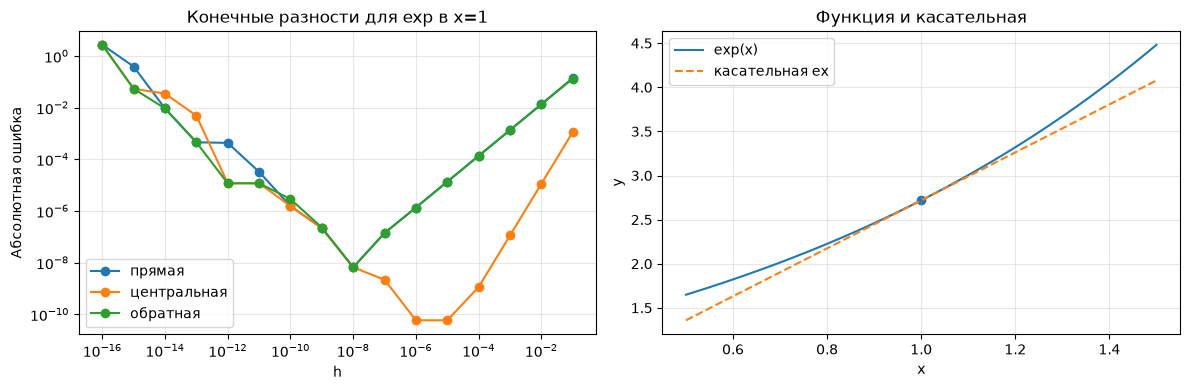

In [5]:
x0 = 1.0
h_values = np.logspace(-1, -16, 16)
exact_derivative = np.exp(x0)
differences = {
    "прямая": (np.exp(x0+h_values)-np.exp(x0))/h_values,
    "центральная": (np.exp(x0+h_values/2)-np.exp(x0-h_values/2))/h_values,
    "обратная": (np.exp(x0)-np.exp(x0-h_values))/h_values,
}
difference_errors = {name: np.abs(values-exact_derivative) for name, values in differences.items()}
print("h | ошибки: прямая, центральная, обратная")
for i, h in enumerate(h_values): print(f"{h:.0e}", *(f"{err[i]:.6e}" for err in difference_errors.values()))
for name, errors in difference_errors.items():
    j = np.argmin(errors)
    print(f"Лучший h ({name}): {h_values[j]:.0e}; ошибка {errors[j]:.6e}")
fig, axes = plt.subplots(1,2,figsize=(12,4))
for name, errors in difference_errors.items(): axes[0].loglog(h_values, errors, "o-", label=name)
axes[0].set(xlabel="h", ylabel="Абсолютная ошибка", title="Конечные разности для exp в x=1")
axes[0].legend(); axes[0].grid(alpha=.3)
xx = np.linspace(.5,1.5,200)
axes[1].plot(xx,np.exp(xx),label="exp(x)");axes[1].plot(xx,np.e*xx,"--",label="касательная ex")
axes[1].scatter([1],[np.e]);axes[1].set(xlabel="x",ylabel="y",title="Функция и касательная")
axes[1].legend();axes[1].grid(alpha=.3);plt.tight_layout();plt.show()


### Задание 2.2. Правила дифференцирования

Источник условий: практикум, с. 71, задачи 1, 2, 4 и 6 (внешний источник условия; в папке отсутствует).

Найдите производные и вычислите их при $x=1$:

$$
\begin{aligned}
&1)\quad y=2x^3-5x^2+7x+4;\\
&2)\quad y=x^2e^x;\\
&3)\quad y=(2x^2+5)^2;\\
&4)\quad y=\ln(2x^3+3x^2).
\end{aligned}
$$

- **[Бумага]** Для каждой функции назовите используемые правила и сохраните производную как функцию от $x$ до подстановки.
- **[Markdown]** Особо выделите внешний и внутренний аргументы в пунктах 3 и 4.
- **[Python]** Проверьте значения центральной разностью при $h=10^{-5}$.
- **[Интерпретация]** Сравните знаки и модули производных как локальные скорости изменения четырёх разных функций.


#### Решение и интерпретация

1. Правила суммы и степени: $y'=6x^2-10x+7$, $y'(1)=3$.
2. Правило произведения: $y'=2xe^x+x^2e^x=e^x(x^2+2x)$, $y'(1)=3e\approx8.154845$.
3. Внешняя функция $u^2$, внутренняя $u=2x^2+5$: $y'=2u\cdot4x=8x(2x^2+5)$, $y'(1)=56$.
4. Внешняя функция $\ln u$, внутренняя $u=2x^3+3x^2$: $y'=(6x^2+6x)/(2x^3+3x^2)$, $y'(1)=12/5=2.4$. Область определения логарифма: $x\in(-3/2,0)\cup(0,+\infty)$.
В x=1 все четыре функции локально возрастают; по величине скорости: 56 > 3e > 3 > 2.4. Это сравнение в заданных числовых шкалах функций. Центральные разности ниже подтверждают значения.


In [6]:
x0 = 1.0
h = 1e-5

functions = [
    lambda x: 2*x**3 - 5*x**2 + 7*x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2*x**2 + 5)**2,
    lambda x: np.log(2*x**3 + 3*x**2),
]

derivatives = [lambda x: 6*x*x-10*x+7, lambda x: np.exp(x)*(x*x+2*x), lambda x: 8*x*(2*x*x+5), lambda x: (6*x*x+6*x)/(2*x**3+3*x*x)]
for i,(function, derivative) in enumerate(zip(functions, derivatives),1):
    exact = derivative(x0)
    numeric = (function(x0+h/2)-function(x0-h/2))/h
    print(i, "аналитически:", exact, "численно:", numeric, "ошибка:", abs(exact-numeric))


1 аналитически: 3.0 численно: 3.0000000002416978 ошибка: 2.4169777290694583e-10
2 аналитически: 8.154845485377136 численно: 8.154845485641715 ошибка: 2.645794694444703e-10
3 аналитически: 56.0 численно: 56.00000000072213 ошибка: 7.221316877803474e-10
4 аналитически: 2.4 численно: 2.400000000046809 ошибка: 4.680922316424585e-11


### Задание 2.3. Дифференциал и граница дифференцируемости

Источник первого условия: практикум, с. 72, задача 2 (внешний источник условия; в папке отсутствует).

Для $y=\ln(1+x^2)$ найдите дифференциал $dy$ и используйте его для приближённого вычисления изменения при переходе от $x=1$ к $x=1.02$.

Затем исследуйте $r(x)=\max(0,x)$ в точке $x=0$.

- **[Бумага]** Найдите $dy=y'(x)dx$, левую и правую производные $r$ в нуле.
- **[Markdown]** Объясните, почему совпадение односторонних пределов необходимо для обычной производной.
- **[Python]** Сравните линейное приближение логарифмической функции с точным изменением; постройте $r(x)$ и её односторонние секущие. Вычислите центральную разность в нуле.
- **[Интерпретация]** Объясните, почему конечная центральная разность может вернуть число даже там, где производная не существует.


#### Решение и интерпретация

$$dy=\frac{2x}{1+x^2}\,dx;\quad x=1,\ dx=0.02\Rightarrow dy=0.02.$$
Точное изменение равно $\ln(1+1.02^2)-\ln2=\ln(1.0202)\approx0.0199986865$; ошибка линейной оценки примерно $1.3135\cdot10^{-6}$. При x=1 вторая производная равна нулю, поэтому здесь остаток начинается с кубического члена.
Для $r(x)=\max(0,x)$ в нуле:
$$r'_-(0)=\lim_{h\downarrow0}\frac{r(0)-r(-h)}h=0,\quad r'_+(0)=\lim_{h\downarrow0}\frac{r(h)-r(0)}h=1.$$
Они различаются, значит обычной производной нет. Симметричная разность $[r(h/2)-r(-h/2)]/h=1/2$ для любого h>0: число существует, но это не производная. График односторонних секущих показывает два разных наклона; вычислительная формула сама по себе не доказывает дифференцируемость.


Линейное, точное изменение, ошибка: 0.02 0.019998686506689123 1.3134933108775726e-06
ReLU: левая, правая, центральная: 0.0 1.0 0.5


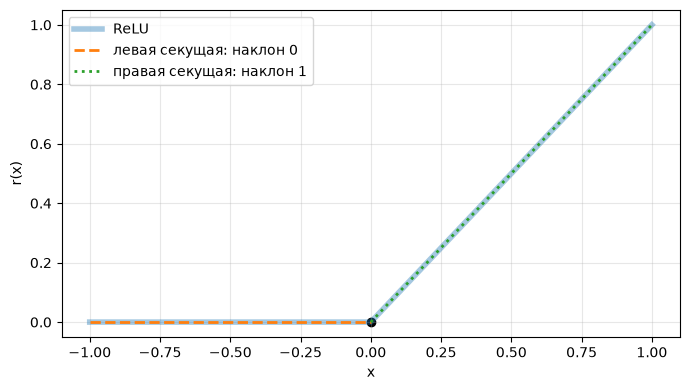

In [7]:
x0, dx = 1.0, 0.02
coefficient = 2*x0/(1+x0*x0)
linear_log_change = coefficient*dx
exact_log_change = np.log1p((x0+dx)**2)-np.log1p(x0*x0)
print("Линейное, точное изменение, ошибка:", linear_log_change, exact_log_change, abs(linear_log_change-exact_log_change))
relu = lambda x: np.maximum(0.0, x)
h = 1e-5
left = (relu(0)-relu(-h))/h
right = (relu(h)-relu(0))/h
central = (relu(h/2)-relu(-h/2))/h
print("ReLU: левая, правая, центральная:", left, right, central)
xx = np.linspace(-1,1,401)
plt.figure(figsize=(7,4));plt.plot(xx,relu(xx),lw=4,alpha=.4,label="ReLU")
plt.plot([-1,0],[0,0],"--",lw=2,label="левая секущая: наклон 0")
plt.plot([0,1],[0,1],":",lw=2,label="правая секущая: наклон 1")
plt.scatter([0],[0],color="black");plt.xlabel("x");plt.ylabel("r(x)");plt.legend();plt.grid(alpha=.3);plt.tight_layout();plt.show()


## 3. Частные производные, градиент и дифференциал


### Короткая теория

Для $f:\mathbb R^n\to\mathbb R$ частная производная меняет только одну координату:

$$
\frac{\partial f}{\partial x_i}
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x)}{h}.
$$

Все частные производные собираются в градиент

$$
\nabla f(\mathbf x)=
\begin{pmatrix}
\partial f/\partial x_1\\ \vdots\\ \partial f/\partial x_n
\end{pmatrix}.
$$

При малом $\Delta\mathbf x$ полный дифференциал задаёт линейное приближение

$$
\Delta f\approx df=\nabla f(\mathbf x)^{\mathsf T}\Delta\mathbf x.
$$

См. [градиент и частные производные, с. 40](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D40).


### Задание 3.1. Полный дифференциал многочлена

Источник условия: практикум, с. 140, задача 1в (внешний источник условия; в папке отсутствует).

Для

$$
z=5x^3+2x^2y^4-6x+9y
$$

найдите $\partial z/\partial x$, $\partial z/\partial y$, градиент и полный дифференциал. Вычислите градиент в точке $(1,-1)$.

- **[Бумага]** При дифференцировании по одной переменной явно обозначьте другую как постоянную.
- **[Markdown]** Запишите $dz$ сначала через частные производные, затем в раскрытом виде.
- **[Python]** Проверьте обе компоненты градиента центральными покоординатными разностями.
- **[Интерпретация]** Объясните, почему коэффициент при $dx$ равен первой компоненте градиента, а коэффициент при $dy$ — второй.


#### Решение и интерпретация

При производной по x считаем y постоянной, а при производной по y — x:
$$z_x=15x^2+4xy^4-6,\qquad z_y=8x^2y^3+9.$$
$$\nabla z=(z_x,z_y)^T\in\mathbb R^2,\qquad dz=z_x\,dx+z_y\,dy=(15x^2+4xy^4-6)dx+(8x^2y^3+9)dy.$$
При $(1,-1)$ получаем $z_x=15+4-6=13$, $z_y=-8+9=1$, то есть $\nabla z=(13,1)^T$ и $dz=13dx+dy$. Коэффициенты дифференциала — скорости изменения по отдельным координатам; именно их собирает градиент. Численная проверка каждой компоненты приведена ниже.


In [8]:
def z_practice(point):
    x, y = point
    return 5*x**3 + 2*x**2*y**4 - 6*x + 9*y

point = np.array([1.0, -1.0])

gradient_exact = np.array([13., 1.])
h = 1e-5
gradient_numeric = np.array([(z_practice(point+h*e/2)-z_practice(point-h*e/2))/h for e in np.eye(2)])
print("Градиенты:", gradient_exact, gradient_numeric)
print("Норма ошибки:", np.linalg.norm(gradient_exact-gradient_numeric))


Градиенты: [13.  1.] [13.  1.]
Норма ошибки: 2.524701893692318e-10


### Задание 3.2. Локальная плоскость вместо касательной

Пусть

$$
f(x,y)=x^2+xy+2y^2-3x+1,
\qquad \mathbf x_0=(1,-1)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla f$, $f(\mathbf x_0)$ и линейную модель $f(\mathbf x_0+\Delta\mathbf x)$.
- **[Markdown]** Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ вычислите прогноз изменения.
- **[Python]** Сравните прогноз с точным изменением. Постройте линии уровня, точку $\mathbf x_0$, градиент и выбранное приращение.
- **[Интерпретация]** Объясните геометрическое различие между касательной к графику одной переменной и касательной плоскостью для двух переменных.


#### Решение и интерпретация

$$\nabla f=(2x+y-3,x+4y)^T,\quad f(1,-1)=1-1+2-3+1=0,$$
$$\nabla f(1,-1)=(-2,-3)^T,\quad f(x_0+\Delta)\approx-2\Delta x-3\Delta y.$$
Касательная плоскость графика: $z=-2(x-1)-3(y+1)$. Для $\Delta=(0.01,-0.02)^T$ прогноз изменения равен $-0.02+0.06=0.04$. Точное изменение:
$$\Delta f=0.04+\Delta x^2+\Delta x\Delta y+2\Delta y^2=0.04+0.0001-0.0002+0.0008=0.0407.$$
Ошибка линейного приближения равна 0.0007. Для одной переменной касательная — прямая в плоскости (x,z), для двух переменных — плоскость в пространстве (x,y,z). На линиях уровня градиент перпендикулярен уровню и указывает локальный рост; маленькое выбранное приращение имеет положительное скалярное произведение с градиентом.


f(x0), градиент: 0.0 [-2. -3.]
Прогноз, точное изменение, ошибка: 0.039999999999999994 0.040699999999999736 0.0006999999999997425


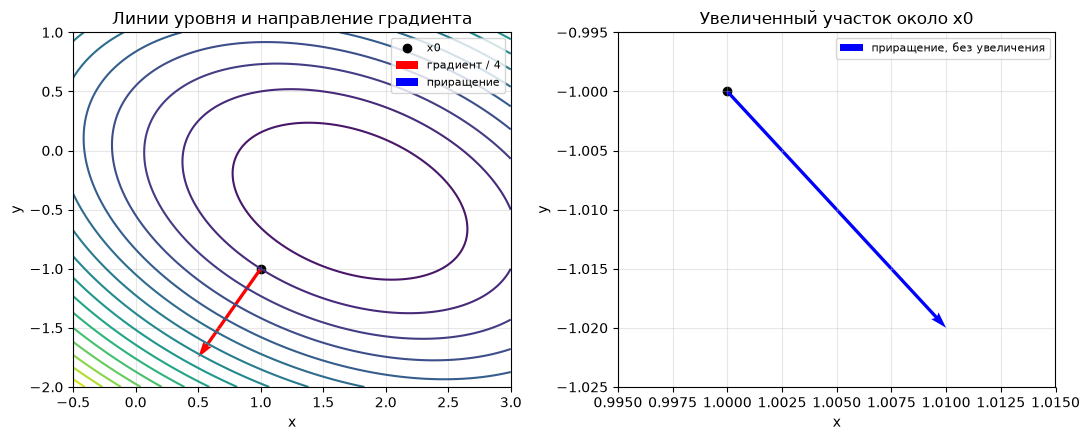

In [9]:
def f_quadratic(point):
    x, y = point
    return x**2 + x*y + 2*y**2 - 3*x + 1

x_base = np.array([1.0, -1.0])
delta = np.array([0.01, -0.02])

gradient_base = np.array([-2., -3.])
linear_change = gradient_base @ delta
exact_change = f_quadratic(x_base+delta)-f_quadratic(x_base)
print("f(x0), градиент:", f_quadratic(x_base), gradient_base)
print("Прогноз, точное изменение, ошибка:", linear_change, exact_change, abs(exact_change-linear_change))
xx,yy = np.meshgrid(np.linspace(-.5,3,200),np.linspace(-2,1,200))
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
axes[0].contour(xx,yy,f_quadratic((xx,yy)),levels=18)
axes[0].scatter(*x_base,color="black",label="x0")
axes[0].quiver(*x_base,*gradient_base,angles="xy",scale_units="xy",scale=4,color="red",label="градиент / 4")
axes[0].quiver(*x_base,*delta,angles="xy",scale_units="xy",scale=1,color="blue",label="приращение")
axes[0].set_title("Линии уровня и направление градиента")
axes[1].scatter(*x_base,color="black")
axes[1].quiver(*x_base,*delta,angles="xy",scale_units="xy",scale=1,color="blue",label="приращение, без увеличения")
axes[1].set(xlim=(.995,1.015),ylim=(-1.025,-.995),title="Увеличенный участок около x0")
for ax in axes: ax.set_xlabel("x");ax.set_ylabel("y");ax.legend(fontsize=8);ax.grid(alpha=.3)
plt.tight_layout();plt.show()


### Задание 3.3. Численный градиент по координатам

- **[Бумага]** Запишите центральную разность для каждой компоненты $\nabla f(\mathbf x)$ через $\mathbf e_i$.
- **[Python]** Реализуйте функцию `central_gradient(f, x, h)`, не зашивая число координат. Проверьте её на функции из задания 3.2 для нескольких $h$.
- **[Markdown]** Сопоставьте аналитический и численный векторы и укажите норму ошибки.
- **[Интерпретация]** Посчитайте число обращений к $f$ для центральной разности в $n$ измерениях и объясните, почему цена растёт с размерностью.


#### Решение и интерпретация

Для базисного вектора $e_i$:
$$[\nabla f(x)]_i\approx\frac{f(x+he_i/2)-f(x-he_i/2)}h.$$
Функция ниже работает для произвольного числа координат n, возвращая массив той же формы. На $f$ из 3.2 результат близок к $(-2,-3)^T$, нормы ошибок напечатаны для нескольких h. У квадратичной функции центральная разность не имеет ошибки усечения в точной арифметике; наблюдаемые отклонения обусловлены округлением и увеличиваются при очень малом h. Нужно 2n обращений к f, поскольку каждую из n координат возмущают в две стороны; стоимость одного обращения тоже может зависеть от n.


**Нормы ошибки:** при h=0.1 — 6.764·10⁻¹⁵, при 10⁻³ — 5.961·10⁻¹³, при 10⁻⁵ — 5.476·10⁻¹¹, при 10⁻⁷ — 5.047·10⁻⁹, при 10⁻⁹ — 2.983·10⁻⁷. Для этой квадратичной функции уменьшение шага ухудшает точность из-за округления.


In [10]:
def central_gradient(function, point, h=1e-5):
    point = np.asarray(point, dtype=float)
    result = np.empty_like(point)
    for index in np.ndindex(point.shape):
        plus, minus = point.copy(), point.copy()
        plus[index] += h/2; minus[index] -= h/2
        result[index] = (function(plus)-function(minus))/h
    return result
for h in [1e-1,1e-3,1e-5,1e-7,1e-9]:
    computed = central_gradient(f_quadratic, x_base, h)
    print(f"h={h:g}", computed, "норма ошибки:", np.linalg.norm(computed-gradient_base))


h=0.1 [-2. -3.] норма ошибки: 6.764165321960921e-15
h=0.001 [-2. -3.] норма ошибки: 5.960650009694253e-13
h=1e-05 [-2. -3.] норма ошибки: 5.4759803027380663e-11
h=1e-07 [-2. -3.] норма ошибки: 5.046693687120374e-09
h=1e-09 [-2. -3.] норма ошибки: 2.98324650188134e-07


## 4. Производная по направлению и полная производная


### Короткая теория

Производная по направлению $\mathbf v$ равна

$$
D_{\mathbf v}f(\mathbf x)
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf v)-f(\mathbf x)}{h}
=\nabla f(\mathbf x)^{\mathsf T}\mathbf v.
$$

При зависимых аргументах используется полная производная:

$$
\frac{dF}{dt}
=\frac{\partial F}{\partial t}
+\frac{\partial F}{\partial x}\frac{dx}{dt}
+\frac{\partial F}{\partial y}\frac{dy}{dt}.
$$

Оба оператора приведены в [теории, с. 40](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D40).


### Задание 4.1. Изменение вдоль выбранного направления

Используйте функцию и точку из задания 3.2, а также единичный вектор

$$
\mathbf v=\frac15(3,4)^{\mathsf T}.
$$

- **[Бумага]** Вычислите $D_{\mathbf v}f(\mathbf x_0)$ и определите, возрастает или убывает функция при движении вдоль $\mathbf v$.
- **[Markdown]** Найдите единичные направления максимального роста и максимального убывания и соответствующие скорости.
- **[Python]** Проверьте направленную производную центральной разностью, меняя только один скаляр $h$.
- **[Интерпретация]** Объясните, почему направление необходимо нормировать, если требуется сравнивать именно скорость на единицу пути.


#### Решение и интерпретация

$\|v\|=\sqrt{9+16}/5=1$,
$$D_v f(x_0)=(-2,-3)\cdot(3/5,4/5)=-18/5=-3.6.$$
Функция убывает при малом положительном движении вдоль v. По неравенству Коши — Буняковского максимальная скорость на единицу длины достигается вдоль градиента:
$$v_{\max}=(-2,-3)^T/\sqrt{13},\quad D_{v_{\max}}f=\sqrt{13};\quad
v_{\min}=(2,3)^T/\sqrt{13},\quad D_{v_{\min}}f=-\sqrt{13}.$$
Если умножить направление на число c, производная тоже умножится на c; без нормировки сравниваются разные скорости параметризации, а не изменение на единицу пути. Центральная разность ниже подтверждает −3.6.


In [11]:
x_base = np.array([1.0, -1.0])
v_direction = np.array([3.0, 4.0]) / 5.0

directional_exact = gradient_base @ v_direction
growth = gradient_base / np.linalg.norm(gradient_base)
decrease = -growth
h = 1e-5
directional_numeric = (f_quadratic(x_base+h*v_direction/2)-f_quadratic(x_base-h*v_direction/2))/h
print("Точно, численно, ошибка:", directional_exact, directional_numeric, abs(directional_exact-directional_numeric))
print("Направления роста, убывания:", growth, decrease)
print("Скорости:", np.linalg.norm(gradient_base), -np.linalg.norm(gradient_base))


Точно, численно, ошибка: -3.6000000000000005 -3.599999999970293 2.970734769291994e-11
Направления роста, убывания: [-0.5547  -0.83205] [0.5547  0.83205]
Скорости: 3.605551275463989 -3.605551275463989


### Задание 4.2. Все пути влияния переменной

Пусть

$$
F(t,x,y)=tx+x^2+xy+2y^2,
\qquad x(t)=t,
\qquad y(t)=t^2.
$$

- **[Бумага]** Найдите $dF/dt$ двумя способами: сначала подставьте $x(t),y(t)$, затем примените формулу полной производной.
- **[Markdown]** В формуле полной производной подпишите прямой путь $t\to F$ и косвенные пути $t\to x\to F$, $t\to y\to F$.
- **[Python]** Сравните оба выражения и центральную разность при $t=1$.
- **[Интерпретация]** Объясните, почему пропуск одного пути зависимости даёт неполную производную.


#### Решение и интерпретация

После подстановки $x=t,y=t^2$:
$$F(t,t,t^2)=2t^2+t^3+2t^4,\quad\frac{dF}{dt}=4t+3t^2+8t^3.$$
Через все пути зависимости:
$$F_t=x\ (t\to F),\quad F_x=t+2x+y\ (t\to x\to F),\quad F_y=x+4y\ (t\to y\to F),$$
$$\frac{dF}{dt}=x+(t+2x+y)\cdot1+(x+4y)\cdot2t=4t+3t^2+8t^3.$$
При t=1 прямой вклад равен 1, путь через x даёт 4, через y — 10; сумма 15. Два аналитических способа и конечная разность совпадают. Пропуск любого пути теряет соответствующее слагаемое, например без прямого вклада получится 14 вместо 15.


In [12]:
def F_total(t, x, y):
    return t*x + x**2 + x*y + 2*y**2

def derivative_substitution(t): return 4*t+3*t*t+8*t**3
def derivative_total(t):
    x, y = t, t*t
    return x + (t+2*x+y)*1 + (x+4*y)*2*t
h = 1e-5
t = 1.
composed = lambda t: F_total(t,t,t*t)
numeric = (composed(t+h/2)-composed(t-h/2))/h
print(derivative_substitution(t), derivative_total(t), numeric)
print("Ошибка:", abs(numeric-derivative_total(t)))


15.0 15.0 15.000000000320311
Ошибка: 3.2031088892381376e-10


## 5. Якобиан, JVP, VJP и цепное правило


### Короткая теория

Для $\mathbf f:\mathbb R^n\to\mathbb R^m$ якобиан имеет размер $m\times n$:

$$
\mathbf J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
\nabla f_1(\mathbf x)^{\mathsf T}\\
\vdots\\
\nabla f_m(\mathbf x)^{\mathsf T}
\end{pmatrix}.
$$

Произведение $\mathbf J\mathbf v$ называется JVP, а $\mathbf u^{\mathsf T}\mathbf J$ — VJP. Для композиции $\mathbf h=\mathbf g\circ\mathbf f$

$$
\mathbf J_{\mathbf h}(\mathbf x)
=\mathbf J_{\mathbf g}(\mathbf f(\mathbf x))\mathbf J_{\mathbf f}(\mathbf x).
$$

См. [якобиан, JVP, VJP и цепное правило, с. 41](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D41).


### Задание 5.1. Якобиан векторной функции

Рассмотрите

$$
\mathbf f(x_1,x_2)=
\begin{pmatrix}
x_1^2+x_2\\
e^{x_1-x_2}\\
x_1x_2
\end{pmatrix}.
$$

- **[Бумага]** Найдите все шесть частных производных и соберите якобиан.
- **[Markdown]** Укажите размерности входа, выхода и якобиана. Вычислите $\mathbf f$ и $\mathbf J_{\mathbf f}$ в точке $\mathbf x_*=(1,0)^{\mathsf T}$.
- **[Python]** Реализуйте `vector_function` и `jacobian_exact`, проверьте строки якобиана покоординатными разностями.
- **[Интерпретация]** Объясните, что означает элемент $J_{ij}$ и почему градиенты компонент выхода расположены по строкам.


#### Решение и интерпретация

Вход имеет размер 2, выход — 3. Все шесть производных:
$$J_f(x)=\begin{pmatrix}2x_1&1\\e^{x_1-x_2}&-e^{x_1-x_2}\\x_2&x_1\end{pmatrix}\in\mathbb R^{3\times2}.$$
В точке $x_*=(1,0)^T$:
$$f(x_*)=(1,e,0)^T,\quad J_f(x_*)=\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}.$$
$J_{ij}=\partial f_i/\partial x_j$ показывает чувствительность i-го выхода к j-му входу. При соглашении $\Delta f\approx J\Delta x$ каждый выход вычисляется своей строкой, поэтому градиенты компонент стоят по строкам в транспонированном виде. Проверяются все строки покоординатными разностями, выводится норма ошибки.


In [13]:
def vector_function(point):
    x1, x2 = point
    return np.array([x1**2+x2, np.exp(x1-x2), x1*x2])
x_star = np.array([1.,0.])
def jacobian_exact(point):
    x1,x2 = point
    exp = np.exp(x1-x2)
    return np.array([[2*x1,1],[exp,-exp],[x2,x1]])
J = jacobian_exact(x_star)
J_numeric = np.stack([central_gradient(lambda p,i=i: vector_function(p)[i],x_star) for i in range(3)])
print("f:",vector_function(x_star)); print("J и J численный:",J,J_numeric,sep="\n")
print("Форма, норма ошибки:",J.shape,np.linalg.norm(J-J_numeric))


f: [1.       2.718282 0.      ]
J и J численный:
[[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
[[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
Форма, норма ошибки: (3, 2) 8.413943275103334e-11


### Задание 5.2. JVP без полного численного якобиана

Пусть $\mathbf v=(1,-2)^{\mathsf T}$.

- **[Бумага]** Вычислите $\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v$.
- **[Markdown]** Запишите центральную аппроксимацию

  $$
  \mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v
  \approx
  \frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-
  \mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
  $$

- **[Python]** Сравните точное и численное JVP для разных $h$, постройте график нормы ошибки.
- **[Интерпретация]** Объясните, почему для численного JVP нужны два обращения к $\mathbf f$ независимо от числа входных координат.


#### Решение и интерпретация

$$J_f(x_*)v=\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}\begin{pmatrix}1\\-2\end{pmatrix}=\begin{pmatrix}0\\3e\\-2\end{pmatrix}\in\mathbb R^3.$$
Аппроксимация: $[f(x_*+hv/2)-f(x_*-hv/2)]/h$. Это производная всех трёх выходов вдоль одного входного направления, которое здесь не нормировано. Требуется ровно два вызова векторной f независимо от числа входных координат, хотя стоимость каждого вызова может расти. Полный численный якобиан потребовал бы 2n вызовов. График показывает уменьшение ошибки и затем влияние округления при слишком малом h.


**Результат:** лучший из проверенных шагов — h=10⁻⁶, норма ошибки 2.832·10⁻¹⁰; при h=10⁻¹² она возрастает до 4.236·10⁻⁴.


h=1e-01; JVP=[ 0.        8.185461 -2.      ]; ошибка=3.061509e-02
h=1e-02; JVP=[-0.        8.155151 -2.      ]; ошибка=3.058101e-04
h=1e-03; JVP=[ 0.        8.154849 -2.      ]; ошибка=3.058067e-06
h=1e-04; JVP=[ 0.        8.154846 -2.      ]; ошибка=3.058255e-08
h=1e-05; JVP=[ 0.        8.154845 -2.      ]; ошибка=3.533973e-10
h=1e-06; JVP=[ 0.        8.154845 -2.      ]; ошибка=2.831889e-10
h=1e-07; JVP=[-0.        8.154845 -2.      ]; ошибка=3.018462e-09
h=1e-08; JVP=[-0.        8.154845 -2.      ]; ошибка=2.270741e-08
h=1e-09; JVP=[ 0.        8.154846 -2.      ]; ошибка=6.557916e-07
h=1e-10; JVP=[ 0.        8.154846 -2.      ]; ошибка=2.022364e-07
h=1e-11; JVP=[ 0.        8.154855 -2.      ]; ошибка=9.084021e-06
h=1e-12; JVP=[ 0.000111  8.155254 -2.      ]; ошибка=4.235731e-04
Точный JVP: [ 0.        8.154845 -2.      ]


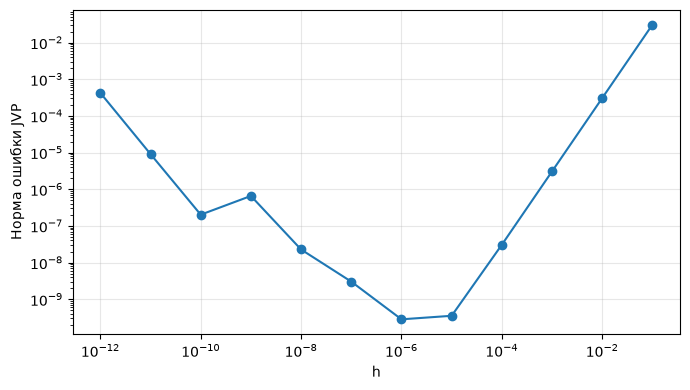

In [14]:
v_jvp = np.array([1.,-2.])
exact_jvp = J @ v_jvp
jvp_steps = np.logspace(-1,-12,12)
jvp_errors = []
for h in jvp_steps:
    numeric = (vector_function(x_star+h*v_jvp/2)-vector_function(x_star-h*v_jvp/2))/h
    error = np.linalg.norm(numeric-exact_jvp)
    jvp_errors.append(error)
    print(f"h={h:.0e}; JVP={numeric}; ошибка={error:.6e}")
print("Точный JVP:",exact_jvp)
plt.figure(figsize=(7,4));plt.loglog(jvp_steps,jvp_errors,"o-");plt.xlabel("h");plt.ylabel("Норма ошибки JVP");plt.grid(alpha=.3);plt.tight_layout();plt.show()


### Задание 5.3. VJP и производная композиции

Сначала для $\mathbf u=(1,2,-1)^{\mathsf T}$ вычислите $\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)$. Затем определите

$$
g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2,
\qquad
\mathbf c=(0,1,1)^{\mathsf T},
\qquad
h(\mathbf x)=g(\mathbf f(\mathbf x)).
$$

- **[Бумага]** Найдите $\nabla_{\mathbf z}g$ и $\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g$ в точке $\mathbf x_*$.
- **[Markdown]** Проверьте размерности каждого множителя и результата цепного правила.
- **[Python]** Сравните аналитический градиент композиции с `central_gradient`.
- **[Интерпретация]** Объясните, как VJP передаёт чувствительность одного скалярного результата ко всем входным координатам.


#### Решение и интерпретация

Для заданного $u\in\mathbb R^3$:
$$u^TJ=(1,2,-1)\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}=(2+2e,-2e)\in\mathbb R^{1\times2}.$$
У $g(z)=\frac12\sum_i(z_i-c_i)^2$ градиент $\nabla_z g=z-c\in\mathbb R^3$. В точке $f(x_*)$: $\nabla_zg=(1,e-1,-1)^T$.
$$\nabla_x h=\underbrace{J_f^T}_{2\times3}\underbrace{(f(x_*)-c)}_{3\times1}
=\begin{pmatrix}2+e(e-1)\\-e(e-1)\end{pmatrix}\in\mathbb R^2.$$
Численно это примерно $(6.670774,-4.670774)^T$; $h(x_*)=1+(e-1)^2/2$. VJP взвешивает строки якобиана чувствительностями скалярного результата к промежуточным выходам; транспонирование даёт градиент-столбец по исходным входам. Заданный u и градиент g — разные векторы весов.


In [15]:
u_vjp = np.array([1.,2.,-1.]);c_target = np.array([0.,1.,1.])
def composition(point):
    residual = vector_function(point)-c_target
    return .5*(residual @ residual)
def composition_gradient(point):
    return jacobian_exact(point).T @ (vector_function(point)-c_target)
g_exact = composition_gradient(x_star)
g_numeric = central_gradient(composition,x_star)
print("VJP:",u_vjp @ J)
print("h(x*):",composition(x_star))
print("Градиенты:",g_exact,g_numeric,"ошибка:",np.linalg.norm(g_exact-g_numeric))


VJP: [ 7.436564 -5.436564]
h(x*): 2.4762462210062797
Градиенты: [ 6.670774 -4.670774] [ 6.670774 -4.670774] ошибка: 3.1474709963359883e-10


## 6. Гессиан и кривизна


### Короткая теория

Гессиан дважды дифференцируемой функции $f:\mathbb R^n\to\mathbb R$ — якобиан градиента:

$$
\mathbf H_f(\mathbf x)=\nabla^2f(\mathbf x)
=\begin{pmatrix}
\frac{\partial^2f}{\partial x_1^2}&\cdots&\frac{\partial^2f}{\partial x_1\partial x_n}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2f}{\partial x_n\partial x_1}&\cdots&\frac{\partial^2f}{\partial x_n^2}
\end{pmatrix}.
$$

В стационарной точке положительно определённый гессиан указывает на локальный минимум, отрицательно определённый — на максимум, а неопределённый — на седловую точку. См. [гессиан, с. 41–42](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D41), [положительно определённые матрицы, с. 13](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D13) и [геометрию квадратичных форм, с. 27](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D27).

![Геометрия квадратичной формы](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/assets/figures/figure-06.png)

*Собственные направления симметричной матрицы задают главные направления кривизны квадратичной формы.*


### Задание 6.1. Положительная кривизна и минимум

Источник условия: практикум, с. 142, задача 1 (внешний источник условия; в папке отсутствует).

Исследуйте на экстремум

$$
z=2x^2+y^2+x-3y+2xy.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, его определитель и собственные значения.
- **[Markdown]** Классифицируйте точку и вычислите значение функции.
- **[Python]** Проверьте решение, постройте линии уровня и отметьте стационарную точку.
- **[Интерпретация]** Свяжите положительные собственные значения с ростом функции во всех достаточно малых направлениях от минимума.


#### Решение и интерпретация

$$\nabla z=(4x+2y+1,2x+2y-3)^T=0.$$
Вычитание второго уравнения из первого: $2x+4=0$, то есть $x=-2$; из $2x+2y-3=0$ следует $y=7/2$.
$$H=\begin{pmatrix}4&2\\2&2\end{pmatrix},\quad\det H=8-4=4,\quad
\det(H-\lambda I)=\lambda^2-6\lambda+4,$$
$$\lambda_{1,2}=3\pm\sqrt5>0.$$
Гессиан положительно определён во всём пространстве, поэтому точка $(-2,7/2)$ — единственный глобальный минимум этой квадратичной функции.
$$z(-2,7/2)=8+49/4-2-21/2-14=-25/4.$$
При любом ненулевом смещении $\Delta z=\frac12\Delta^TH\Delta>0$; положительные собственные значения означают рост вдоль всех направлений. Численная проверка и эллиптические линии уровня подтверждают вывод.


Точка, значение, градиент: [-2.   3.5] -6.25 [0. 0.]
Гессиан, det, собственные значения:
[[4. 2.]
 [2. 2.]]
4.0
[0.763932 5.236068]


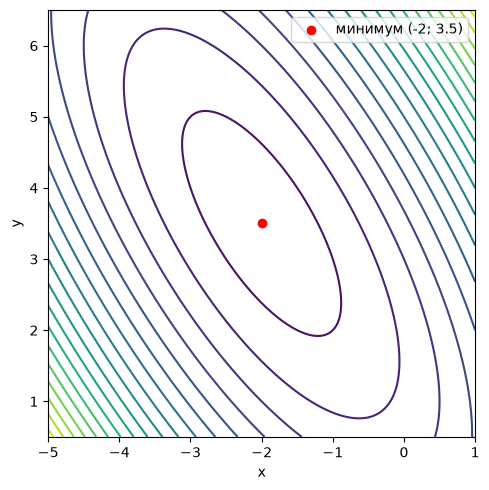

In [16]:
def minimum_function(point):
    x, y = point
    return 2*x**2 + y**2 + x - 3*y + 2*x*y

minimum_point = np.array([-2.,3.5])
minimum_hessian = np.array([[4.,2.],[2.,2.]])
print("Точка, значение, градиент:", minimum_point, minimum_function(minimum_point), minimum_hessian @ minimum_point + [1,-3])
print("Гессиан, det, собственные значения:",minimum_hessian,np.linalg.det(minimum_hessian),np.linalg.eigvalsh(minimum_hessian),sep="\n")
xx,yy=np.meshgrid(np.linspace(-5,1,200),np.linspace(.5,6.5,200))
plt.figure(figsize=(6,5));plt.contour(xx,yy,minimum_function((xx,yy)),levels=20)
plt.scatter(*minimum_point,color="red",label="минимум (-2; 3.5)");plt.xlabel("x");plt.ylabel("y");plt.legend();plt.gca().set_aspect("equal");plt.tight_layout();plt.show()


### Задание 6.2. Неопределённая кривизна и седло

Источник условия: практикум, с. 142, задача 3 (внешний источник условия; в папке отсутствует).

Исследуйте

$$
z=x^2-2y^2-4xy+3x.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, определитель и собственные значения.
- **[Markdown]** Покажите два направления, вдоль которых квадратичное изменение имеет разные знаки.
- **[Python]** Постройте линии уровня и трёхмерную поверхность около стационарной точки.
- **[Интерпретация]** Объясните, почему нулевой градиент ещё не гарантирует минимум.


#### Решение и интерпретация

$$\nabla z=(2x-4y+3,-4x-4y)^T=0.$$
Из второго уравнения $y=-x$, затем $6x+3=0$, значит $x=-1/2,y=1/2$; значение $z=-3/4$.
$$H=\begin{pmatrix}2&-4\\-4&-4\end{pmatrix},\quad\det H=-8-16=-24,$$
$$\det(H-\lambda I)=\lambda^2+2\lambda-24=(\lambda-4)(\lambda+6).$$
Собственные значения 4 и −6 имеют разные знаки: это седло. Например, при смещении $(t,0)$ изменение равно $t^2>0$, а при $(0,t)$ — $-2t^2<0$ (t≠0). Нулевой градиент устраняет линейное изменение, но не определяет знаки квадратичных изменений. На поверхности и линиях уровня видны направления роста и убывания.


Точка, значение, градиент: [-0.5  0.5] -0.75 [0. 0.]
Гессиан, det, собственные значения:
[[ 2. -4.]
 [-4. -4.]]
-23.999999999999993
[-6.  4.]
Направление и квадратичное изменение: [1. 0.] 1.0
Направление и квадратичное изменение: [0. 1.] -2.0


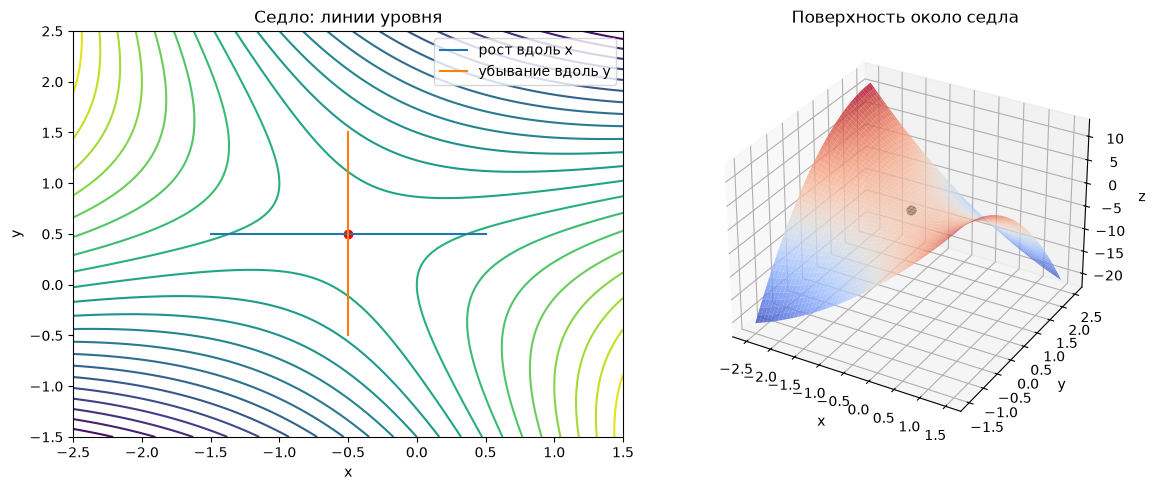

In [17]:
def saddle_function(point):
    x, y = point
    return x**2 - 2*y**2 - 4*x*y + 3*x

saddle_point = np.array([-.5,.5])
saddle_hessian = np.array([[2.,-4.],[-4.,-4.]])
print("Точка, значение, градиент:",saddle_point,saddle_function(saddle_point),saddle_hessian @ saddle_point + [3,0])
print("Гессиан, det, собственные значения:",saddle_hessian,np.linalg.det(saddle_hessian),np.linalg.eigvalsh(saddle_hessian),sep="\n")
for direction in np.eye(2): print("Направление и квадратичное изменение:",direction,.5*direction @ saddle_hessian @ direction)
xx,yy=np.meshgrid(np.linspace(-2.5,1.5,100),np.linspace(-1.5,2.5,100));zz=saddle_function((xx,yy))
fig=plt.figure(figsize=(12,5));ax=fig.add_subplot(121);ax.contour(xx,yy,zz,levels=25)
ax.scatter(*saddle_point,color="red");ax.set(xlabel="x",ylabel="y",title="Седло: линии уровня")
ax.plot([saddle_point[0]-1,saddle_point[0]+1],[saddle_point[1]]*2,label="рост вдоль x")
ax.plot([saddle_point[0]]*2,[saddle_point[1]-1,saddle_point[1]+1],label="убывание вдоль y");ax.legend()
ax=fig.add_subplot(122,projection="3d");ax.plot_surface(xx,yy,zz,cmap="coolwarm",alpha=.8)
ax.scatter(*saddle_point,saddle_function(saddle_point),color="black",s=40)
ax.set(xlabel="x",ylabel="y",zlabel="z",title="Поверхность около седла");plt.tight_layout();plt.show()


### Задание 6.3. Квадратичная модель и HVP

Пусть

$$
\varphi(x,y)=e^{x+2y}+x^2,
\qquad \mathbf x_0=(0,0)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla\varphi(\mathbf x_0)$, $\mathbf H_\varphi(\mathbf x_0)$ и второе приближение

  $$
  \varphi(\mathbf x_0+\Delta)
  \approx \varphi(\mathbf x_0)
  +\nabla\varphi(\mathbf x_0)^{\mathsf T}\Delta
  +\frac12\Delta^{\mathsf T}\mathbf H_\varphi(\mathbf x_0)\Delta
  $$

  для $\Delta=(0.1,0.1)^{\mathsf T}$.
- **[Markdown]** Для $\mathbf v=(1,-1)^{\mathsf T}$ вычислите $\mathbf H\mathbf v$.
- **[Python]** Проверьте HVP центральной разностью градиента и сравните точное значение функции с линейным и квадратичным приближениями при уменьшающемся масштабе $\Delta$.
- **[Интерпретация]** Объясните, какую дополнительную информацию даёт квадратичный член по сравнению с одним градиентом.


#### Решение и интерпретация

Обозначим $a=e^{x+2y}$:
$$\nabla\varphi=(a+2x,2a)^T,\quad H_\varphi=\begin{pmatrix}a+2&2a\\2a&4a\end{pmatrix}.$$
При $(0,0)$: $\varphi=1$, $\nabla\varphi=(1,2)^T$, $H=\begin{pmatrix}3&2\\2&4\end{pmatrix}$.
Для $\Delta=(0.1,0.1)^T$ линейный член равен 0.3, а $\frac12\Delta^TH\Delta=0.055$; линейное приближение — 1.3, квадратичное — 1.355, точное значение $e^{0.3}+0.01\approx1.359858808$.
$$H(1,-1)^T=(1,-2)^T.$$
Проверка HVP использует $[\nabla\varphi(x_0+hv/2)-\nabla\varphi(x_0-hv/2)]/h$. Квадратичный член учитывает изменение самого градиента, то есть кривизну. При уменьшении масштаба смещения линейная ошибка здесь имеет порядок $O(\|\Delta\|^2)$, а квадратичная — $O(\|\Delta\|^3)$; численная таблица показывает это поведение.


In [18]:
def phi(point):
    x,y=point
    return np.exp(x+2*y)+x*x
def phi_gradient(point):
    x,y=point;a=np.exp(x+2*y)
    return np.array([a+2*x,2*a])
def phi_hessian(point):
    x,y=point;a=np.exp(x+2*y)
    return np.array([[a+2,2*a],[2*a,4*a]])
phi_base=np.zeros(2);phi_delta=np.array([.1,.1]);v_hvp=np.array([1.,-1.]);h=1e-5
H_phi=phi_hessian(phi_base)
hvp_numeric=(phi_gradient(phi_base+h*v_hvp/2)-phi_gradient(phi_base-h*v_hvp/2))/h
print("Градиент, H:",phi_gradient(phi_base),H_phi,sep="\n")
print("HVP точно, численно, ошибка:",H_phi@v_hvp,hvp_numeric,np.linalg.norm(H_phi@v_hvp-hvp_numeric))
print("масштаб | точное | линейное | квадратичное | ошибки L и Q")
for scale in [1.,.5,.25,.125,.0625]:
    d=scale*phi_delta;exact=phi(phi_base+d)
    linear=phi(phi_base)+phi_gradient(phi_base)@d
    quadratic=linear+.5*d@H_phi@d
    print(f"{scale:.4f} | {exact:.10f} | {linear:.10f} | {quadratic:.10f} | {abs(exact-linear):.4e} | {abs(exact-quadratic):.4e}")


Градиент, H:
[1. 2.]
[[3. 2.]
 [2. 4.]]
HVP точно, численно, ошибка: [ 1. -2.] [ 1. -2.] 1.3870326126750647e-11
масштаб | точное | линейное | квадратичное | ошибки L и Q
1.0000 | 1.3598588076 | 1.3000000000 | 1.3550000000 | 5.9859e-02 | 4.8588e-03
0.5000 | 1.1643342427 | 1.1500000000 | 1.1637500000 | 1.4334e-02 | 5.8424e-04
0.2500 | 1.0785091509 | 1.0750000000 | 1.0784375000 | 3.5092e-03 | 7.1651e-05
0.1250 | 1.0383682471 | 1.0375000000 | 1.0383593750 | 8.6825e-04 | 8.8721e-06
0.0625 | 1.0189659476 | 1.0187500000 | 1.0189648438 | 2.1595e-04 | 1.1038e-06


## 7. Матричное дифференцирование


### Короткая теория

Для векторного аргумента полезны тождества

$$
\frac{\partial(\mathbf a^{\mathsf T}\mathbf x)}{\partial\mathbf x}=\mathbf a,
\qquad
\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}
=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x.
$$

Для матричного аргумента производная скалярной функции имеет ту же форму, что и матрица:

$$
\left(\frac{\partial f}{\partial\mathbf X}\right)_{ij}
=\frac{\partial f}{\partial X_{ij}}.
$$

В частности,

$$
\frac{\partial}{\partial\mathbf X}
(\mathbf a^{\mathsf T}\mathbf X\mathbf b)
=\mathbf a\mathbf b^{\mathsf T},
\qquad
\frac{\partial}{\partial\mathbf X}
\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A.
$$

См. [векторные градиенты, с. 42](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D42) и [матричные и следовые тождества, с. 42–43](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D42).


### Задание 7.1. Линейно-квадратичная форма

Для

$$
f(\mathbf x)=\mathbf a^{\mathsf T}\mathbf x+\mathbf x^{\mathsf T}\mathbf A\mathbf x,
$$

$$
\mathbf A=\begin{pmatrix}2&-1\\3&1\end{pmatrix},
\quad
\mathbf a=\begin{pmatrix}1\\-2\end{pmatrix},
\quad
\mathbf x=\begin{pmatrix}2\\-1\end{pmatrix},
$$

найдите значение, градиент и гессиан.

- **[Бумага]** Сначала раскройте выражение покоординатно, затем примените матричное тождество.
- **[Markdown]** Объясните появление симметричной части $\mathbf A+\mathbf A^{\mathsf T}$.
- **[Python]** Проверьте градиент и гессиан конечными разностями.
- **[Интерпретация]** Покажите, что кососимметричная часть $\mathbf A$ не влияет на $\mathbf x^{\mathsf T}\mathbf A\mathbf x$.


#### Решение и интерпретация

Раскроем форму:
$$f(x_1,x_2)=x_1-2x_2+2x_1^2+2x_1x_2+x_2^2.$$
При $(2,-1)$ линейная часть равна 4, квадратичная — $8-4+1=5$, поэтому $f=9$.
$$\nabla f=\begin{pmatrix}1+4x_1+2x_2\\-2+2x_1+2x_2\end{pmatrix}
=a+(A+A^T)x,\quad\nabla f(2,-1)=(7,0)^T,$$
$$H=A+A^T=\begin{pmatrix}4&2\\2&2\end{pmatrix}.$$
В индексной форме дифференцирование $\sum_{ij}x_i A_{ij}x_j$ по $x_l$ даёт $\sum_j A_{lj}x_j+\sum_i x_iA_{il}$: переменная присутствует в двух множителях, отсюда симметричная сумма.
$A=S+K$, где $S=(A+A^T)/2$, $K=(A-A^T)/2=\begin{pmatrix}0&-2\\2&0\end{pmatrix}$. Скаляр $x^TKx$ равен своему транспонированию $x^TK^Tx=-x^TKx$, значит равен нулю при любом x. Поэлементная проверка градиента и конечные разности аналитического градиента для H приведены ниже.


In [19]:
A_quad = np.array([[2, -1], [3, 1]], dtype=float)
a_quad = np.array([1.0, -2.0])
x_quad = np.array([2.0, -1.0])

quadratic_form=lambda x:a_quad@x+x@A_quad@x
quadratic_gradient=lambda x:a_quad+(A_quad+A_quad.T)@x
quadratic_hessian=A_quad+A_quad.T
g_numeric=central_gradient(quadratic_form,x_quad)
h=1e-5
H_numeric=np.column_stack([(quadratic_gradient(x_quad+h*e/2)-quadratic_gradient(x_quad-h*e/2))/h for e in np.eye(2)])
print("Значение, градиент, H:",quadratic_form(x_quad),quadratic_gradient(x_quad),quadratic_hessian,sep="\n")
print("Численные градиент и H:",g_numeric,H_numeric,sep="\n")
print("Ошибки:",np.linalg.norm(g_numeric-quadratic_gradient(x_quad)),np.linalg.norm(H_numeric-quadratic_hessian))
print("Вклад кососимметричной части:",x_quad@((A_quad-A_quad.T)/2)@x_quad)


Значение, градиент, H:
9.0
[7. 0.]
[[4. 2.]
 [2. 2.]]
Численные градиент и H:
[7. 0.]
[[4. 2.]
 [2. 2.]]
Ошибки: 3.19032971483978e-10 1.0394754413362304e-10
Вклад кососимметричной части: 0.0


### Задание 7.2. Производная по матрице

Пусть

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b,
\quad
\mathbf a=(1,-2)^{\mathsf T},
\quad
\mathbf b=(3,1,-1)^{\mathsf T},
$$

$$
\mathbf M=
\begin{pmatrix}1&2&0\\-1&3&4\end{pmatrix}.
$$

- **[Бумага]** Раскройте $s=\sum_i\sum_j a_iM_{ij}b_j$ и найдите каждую $\partial s/\partial M_{ij}$.
- **[Markdown]** Сверните результат в $\mathbf a\mathbf b^{\mathsf T}$ и перепишите скаляр через след.
- **[Python]** Изменяйте каждый элемент $M_{ij}$ отдельно и сравните численный градиент с внешним произведением.
- **[Интерпретация]** Объясните, почему форма градиента совпадает с формой матрицы параметров.


#### Решение и интерпретация

$$s=3M_{11}+M_{12}-M_{13}-6M_{21}-2M_{22}+2M_{23}.$$
При заданной M: $s=3+2-0+6-6+8=13$. Все шесть производных — коэффициенты соответствующих элементов:
$$\nabla_Ms=ab^T=\begin{pmatrix}3&1&-1\\-6&-2&2\end{pmatrix}\in\mathbb R^{2\times3}.$$
Скаляр можно записать через след:
$$s=\operatorname{tr}(a^TMb)=\operatorname{tr}(ba^TM)=\operatorname{tr}((ab^T)^TM).$$
Поскольку $ds=\sum_{ij}(\partial s/\partial M_{ij})dM_{ij}=\langle\nabla_Ms,dM\rangle_F$, каждому параметру соответствует один элемент градиента с теми же индексами и формой. Численно возмущаются все шесть элементов отдельно.


In [20]:
a_matrix = np.array([1.0, -2.0])
b_matrix = np.array([3.0, 1.0, -1.0])
M_parameter = np.array([[1, 2, 0], [-1, 3, 4]], dtype=float)

matrix_scalar=lambda M:a_matrix@M@b_matrix
g_matrix=np.outer(a_matrix,b_matrix)
g_numeric=central_gradient(matrix_scalar,M_parameter)
print("s:",matrix_scalar(M_parameter))
print("Градиенты:",g_matrix,g_numeric,sep="\n")
print("Максимальная ошибка, норма:",np.max(np.abs(g_matrix-g_numeric)),np.linalg.norm(g_matrix-g_numeric))


s: 13.0
Градиенты:
[[ 3.  1. -1.]
 [-6. -2.  2.]]
[[ 3.  1. -1.]
 [-6. -2.  2.]]
Максимальная ошибка, норма: 1.2812417793384157e-10 2.0891844782760654e-10


### Задание 7.3. Сумма потерь, след и матричный градиент

Для общего пакета данных определим

$$
Q(\mathbf W)=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2.
$$

- **[Бумага]** Запишите $Q$ тремя способами:

  $$
  Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K
  \left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2,
  $$

  через норму Фробениуса и через след.
- **[Markdown]** Выведите по индексам

  $$
  \nabla_{\mathbf W}Q
  =\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)
  $$

  и действие гессиана на матрицу-направление $\Delta\mathbf W$.
- **[Python]** Вычислите $Q(\mathbf W_0)$, градиент и проверьте каждый элемент конечными разностями.
- **[Интерпретация]** Сопоставьте индексы $d,k$ у градиента индексам параметра $W_{dk}$.


#### Решение и интерпретация

Положим $R=XW-Y\in\mathbb R^{N\times K}$, где N=4, D=3, K=2. Три записи:
$$Q=\frac1{2N}\sum_{n=1}^N\sum_{k=1}^K\left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2
=\frac1{2N}\|R\|_F^2=\frac1{2N}\operatorname{tr}(R^TR).$$
Для фиксированных p,q:
$$\frac{\partial Q}{\partial W_{pq}}=\frac1N\sum_{nk}R_{nk}\frac{\partial R_{nk}}{\partial W_{pq}}
=\frac1N\sum_{nk}R_{nk}X_{np}\delta_{kq}=\frac1N\sum_n X_{np}R_{nq}.$$
Следовательно, $\nabla_WQ=X^T(XW-Y)/N\in\mathbb R^{3\times2}$, а действие гессиана:
$$\mathcal H_Q[\Delta W]=\frac1N X^TX\Delta W\in\mathbb R^{3\times2}.$$
В индексах второго порядка $\partial^2Q/(\partial W_{pq}\partial W_{rs})=(X^TX)_{pr}\delta_{qs}/N$. Полный гессиан можно считать тензором 3×2×3×2 или матрицей 6×6 после согласованной развёртки, но для действия на направление он не нужен. Индексы p,q (или d,k) у градиента совпадают с индексами параметра. Ниже приведены Q, градиент и проверка каждого элемента, а также HVP.


**Численный результат:** $Q(W_0)=0.3775$,
$$\nabla_WQ(W_0)=\begin{pmatrix}0.125&-0.425\\-0.2&-0.2\\-0.325&0.325\end{pmatrix}.$$
Максимальная поэлементная ошибка равна 6.370·10⁻¹², норма ошибки — 8.607·10⁻¹²; проверка действия гессиана дала норму ошибки 1.324·10⁻¹¹.


In [21]:
def matrix_least_squares(W):
    residual = X_data @ W - Y_data
    return 0.5 * np.sum(residual**2) / len(X_data)

def matrix_least_squares_gradient(W):return X_data.T@(X_data@W-Y_data)/len(X_data)
def matrix_least_squares_hvp(delta_W):return X_data.T@X_data@delta_W/len(X_data)
q_value=matrix_least_squares(W_initial)
q_gradient=matrix_least_squares_gradient(W_initial)
q_numeric=central_gradient(matrix_least_squares,W_initial)
print("Q:",q_value);print("Градиенты:",q_gradient,q_numeric,sep="\n")
print("Максимальная ошибка, норма:",np.max(np.abs(q_gradient-q_numeric)),np.linalg.norm(q_gradient-q_numeric))
delta_W=np.arange(6,dtype=float).reshape(3,2)/5;h=1e-5
q_hvp=matrix_least_squares_hvp(delta_W)
q_hvp_numeric=(matrix_least_squares_gradient(W_initial+h*delta_W/2)-matrix_least_squares_gradient(W_initial-h*delta_W/2))/h
print("HVP:",q_hvp,"ошибка:",np.linalg.norm(q_hvp-q_hvp_numeric))


Q: 0.3775
Градиенты:
[[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
[[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
Максимальная ошибка, норма: 6.370043381664914e-12 8.606501734706707e-12
HVP: [[-0.5 -0.5]
 [ 1.2  1.6]
 [ 0.9  1.1]] ошибка: 1.3242970406541532e-11


## 8. Сквозная составная функция


### Короткая теория

Для сигмоиды

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).
$$

В матричном выражении нелинейная функция применяется поэлементно. Чтобы не смешивать матричное и поэлементное умножение, будем обозначать последнее символом $\odot$.

Цепное правило для композиции применяется от скалярного результата к каждому промежуточному аргументу. Это та же идея, что произведение якобианов и VJP на [с. 41](../%D0%9B%D0%B8%D0%BD%D0%B5%D0%B8%CC%86%D0%BD%D0%B0%D1%8F%20%D0%B0%D0%BB%D0%B3%D0%B5%D0%B1%D1%80%D0%B0%20-%20%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D0%B0%D1%8F%20%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0/linear-algebra.pdf#page%3D41), но записанная сразу в формах нужных массивов.


### Задание 8.1. Прямое вычисление и размерности

- **[Бумага]** Для элемента $Z_{nk}$ запишите

  $$
  Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k.
  $$

  Затем запишите $H_{nk}$ и $\mathcal L$ как суммы по индексам.
- **[Markdown]** Составьте таблицу объектов $\mathbf X,\mathbf W,\mathbf b,\mathbf Z,\mathbf H,\mathbf Y,\mathcal L$ с размерностями и типами.
- **[Python]** Выполните прямое вычисление с начальными параметрами. Для устойчивости ограничьте аргумент `exp` диапазоном `[-50, 50]`.
- **[Интерпретация]** Объясните, почему добавление $\mathbf b$ к каждой строке является расширением по строкам, а не матричным произведением двух исходных массивов.


#### Решение и интерпретация

$$Z_{nk}=\sum_{d=1}^3X_{nd}W_{dk}+b_k,\quad H_{nk}=\frac1{1+e^{-Z_{nk}}},$$
$$\mathcal L=\frac1{2\cdot4}\sum_{n=1}^4\sum_{k=1}^2(H_{nk}-Y_{nk})^2+\frac{0.05}{2}\sum_{d=1}^3\sum_{k=1}^2 W_{dk}^2.$$

| Объект | Тип | Размер |
|---|---|---|
| X | матрица входов | 4×3 |
| W | матрица параметров | 3×2 |
| b | вектор смещений | 2×1 математически, `(2,)` в NumPy |
| Z | матрица линейных выходов | 4×2 |
| H | матрица нелинейных выходов | 4×2 |
| Y | матрица целей | 4×2 |
| L | скаляр | `()` |

Например, $Z_{11}=1\cdot0.2+0\cdot0.4+(-1)(-0.5)+0.1=0.8$; вся матрица
$$Z=\begin{pmatrix}0.8&-0.7\\0&0.1\\0.7&-0.4\\0.2&0.5\end{pmatrix}.$$
Операция `X @ W + b` распространяет один и тот же вектор b на каждую строку Z. Это broadcasting, эквивалентный прибавлению $1_Nb^T$; сами массивы b и X при этом не перемножаются. Код использует ограничение аргумента экспоненты, заданное шаблоном. Все исследуемые Z остаются строго внутри (−50,50), поэтому ограничение не влияет на вычисленные значения и производные; вне этого диапазона производная клиппированной реализации потребовала бы отдельного учёта.


**Значения в начальной точке:**
$$H\approx\begin{pmatrix}0.689974&0.331812\\0.500000&0.524979\\0.668188&0.401312\\0.549834&0.622459\end{pmatrix}.$$
Потеря на данных равна 0.1204891043, штраф — 0.01475, полная $\mathcal L_0=0.1352391043$.


In [22]:
N=len(X_data)
Z_initial=X_data@W_initial+b_initial
H_initial=sigmoid(Z_initial)
loss_data=.5*np.sum((H_initial-Y_data)**2)/N
loss_regularization=.5*regularization*np.sum(W_initial**2)
loss_initial=loss_data+loss_regularization
print("Z и H:",Z_initial,H_initial,sep="\n")
print("Потеря данных, регуляризация, L:",loss_data,loss_regularization,loss_initial)
for label,value in [("X",X_data),("W",W_initial),("b",b_initial),("Z",Z_initial),("H",H_initial),("Y",Y_data),("L",np.asarray(loss_initial))]:print(label,value.shape)
print("Z[0,0] вручную:",1*.2+0*.4+(-1)*(-.5)+.1)
assert np.all(np.abs(Z_initial)<50)


Z и H:
[[ 0.8 -0.7]
 [ 0.   0.1]
 [ 0.7 -0.4]
 [ 0.2  0.5]]
[[0.689974 0.331812]
 [0.5      0.524979]
 [0.668188 0.401312]
 [0.549834 0.622459]]
Потеря данных, регуляризация, L: 0.12048910430482579 0.014750000000000003 0.1352391043048258
X (4, 3)
W (3, 2)
b (2,)
Z (4, 2)
H (4, 2)
Y (4, 2)
L ()
Z[0,0] вручную: 0.7999999999999999


### Задание 8.2. Распространение производных по композиции

Обозначьте $\mathbf R=\mathbf H-\mathbf Y$.

- **[Бумага]** Последовательно получите

  $$
  \mathbf G_H=\frac{1}{N}\mathbf R,
  \qquad
  \mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H),
  $$

  $$
  \nabla_{\mathbf W}\mathcal L
  =\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W,
  \qquad
  \nabla_{\mathbf b}\mathcal L
  =\mathbf G_Z^{\mathsf T}\mathbf1_N.
  $$
- **[Markdown]** После каждой строки подпишите размерность. Отдельно объясните происхождение $\lambda\mathbf W$.
- **[Python]** Реализуйте одну функцию, возвращающую $\mathcal L$, $\nabla_{\mathbf W}\mathcal L$ и $\nabla_{\mathbf b}\mathcal L$.
- **[Интерпретация]** Опишите вычисление производных как движение по композиции в порядке, обратном прямому вычислению значений.


#### Решение и интерпретация

Дифференцируем сумму квадратов по каждому $H_{nk}$: множитель 2 сокращает 1/2, поэтому
$$G_H=(H-Y)/N\quad(4\times2).$$
По цепному правилу и $\sigma'(z)=\sigma(z)(1-\sigma(z))$:
$$G_Z=G_H\odot H\odot(1-H)\quad(4\times2).$$
Так как $\partial Z_{nk}/\partial W_{dq}=X_{nd}\delta_{kq}$,
$$\frac{\partial\mathcal L}{\partial W_{dq}}=\sum_n X_{nd}(G_Z)_{nq}+\lambda W_{dq},\qquad
\nabla_W\mathcal L=X^TG_Z+\lambda W\quad(3\times2).$$
Регуляризация равна $\lambda\sum_{dk}W_{dk}^2/2$, её производная — $\lambda W$; b не штрафуется.
Поскольку каждый $b_k$ прибавляется ко всем строкам,
$$\frac{\partial\mathcal L}{\partial b_k}=\sum_n(G_Z)_{nk},\quad\nabla_b\mathcal L=G_Z^T1_N\quad(2\times1).$$
Прямой проход идёт от W,b к Z, H и скаляру L, обратный — от L к чувствительности по H, затем Z, затем W,b. Используются локальные произведения и суммы без построения полного якобиана всех промежуточных элементов.


**Начальные градиенты:**
$$\nabla_W\mathcal L\approx\begin{pmatrix}0.012147&-0.024566\\0.066950&-0.001038\\-0.035867&0.046140\end{pmatrix},\qquad
\nabla_b\mathcal L\approx(0.045317,-0.015683)^T.$$
На всех траекториях максимальный |Z| меньше 4.183, поэтому использованная защитная маска клиппирования в коде везде равна единице и результаты соответствуют выведенным формулам.


In [23]:
def objective_and_grad(W,b):
    Z=X_data@W+b
    H=sigmoid(Z)
    R=H-Y_data
    loss=.5*np.sum(R**2)/len(X_data)+.5*regularization*np.sum(W**2)
    G_H=R/len(X_data)
    G_Z=G_H*H*(1-H)
    # За пределами клиппирования производная реализованной сигмоиды равна нулю.
    G_Z=G_Z*(np.abs(Z)<50)
    grad_W=X_data.T@G_Z+regularization*W
    grad_b=G_Z.sum(axis=0)
    return loss,grad_W,grad_b
initial_loss,initial_grad_W,initial_grad_b=objective_and_grad(W_initial,b_initial)
print("L:",initial_loss)
print("grad_W",initial_grad_W.shape,initial_grad_W,sep="\n")
print("grad_b",initial_grad_b.shape,initial_grad_b,sep="\n")


L: 0.1352391043048258
grad_W
(3, 2)
[[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
grad_b
(2,)
[ 0.045317 -0.015683]


### Задание 8.3. Проверка каждого параметра

- **[Бумага]** Запишите центральную разность для одного элемента $W_{dk}$ и одного элемента $b_k$.
- **[Python]** Реализуйте универсальную численную проверку, поочерёдно возмущающую каждый элемент $\mathbf W$ и $\mathbf b$ при $h=10^{-6}$.
- **[Markdown]** Выведите аналитические и численные градиенты, максимальную абсолютную и относительную ошибки.
- **[Интерпретация]** Если проверка не проходит, перечислите порядок диагностики: коэффициент $1/N$, знак остатка, производная сигмоиды, транспонирование, сумма по строкам и регуляризация.


#### Решение и интерпретация

Для матрицы $E^{(dq)}$ с единственной единицей и базисного $e_k$:
$$\frac{\partial\mathcal L}{\partial W_{dq}}\approx\frac{\mathcal L(W+hE^{(dq)}/2,b)-\mathcal L(W-hE^{(dq)}/2,b)}h,$$
$$\frac{\partial\mathcal L}{\partial b_k}\approx\frac{\mathcal L(W,b+he_k/2)-\mathcal L(W,b-he_k/2)}h.$$
Проверены все 6 весов и 2 смещения при h=10⁻⁶, то есть 16 вычислений L. Используются максимальная абсолютная ошибка и максимальная поэлементная относительная ошибка $|g_i-\widetilde g_i|/\max(10^{-12},|g_i|,|\widetilde g_i|)$; отдельно приведена нормированная ошибка всего вектора. Числа и оба массива градиентов выведены ниже, абсолютная ошибка проверяется условием <10⁻⁶.
Порядок диагностики расхождения: (1) делитель N, а не NK; (2) остаток H−Y; (3) множитель H(1−H); (4) транспонирование X; (5) суммирование смещения по строкам; (6) добавление λW только к весам; затем шаг разности, округление и попадание Z в область клиппирования. Проверка в точке не заменяет аналитического вывода.


**Результат проверки:** максимальная абсолютная ошибка 3.3523·10⁻¹¹, максимальная относительная — 6.3195·10⁻⁹, нормированная ошибка объединённого вектора — 2.3027·10⁻¹⁰. Требование абсолютной ошибки <10⁻⁶ выполнено с большим запасом; ниже сохранены аналитические и численные значения каждого параметра.


In [24]:
def numerical_parameter_gradients(W,b,h=1e-6):
    grad_W=central_gradient(lambda W_trial:objective_and_grad(W_trial,b)[0],W,h)
    grad_b=central_gradient(lambda b_trial:objective_and_grad(W,b_trial)[0],b,h)
    return grad_W,grad_b
numeric_grad_W,numeric_grad_b=numerical_parameter_gradients(W_initial,b_initial)
analytic_flat=np.concatenate([initial_grad_W.ravel(),initial_grad_b])
numeric_flat=np.concatenate([numeric_grad_W.ravel(),numeric_grad_b])
absolute_errors=np.abs(analytic_flat-numeric_flat)
relative_errors=absolute_errors/np.maximum(1e-12,np.maximum(np.abs(analytic_flat),np.abs(numeric_flat)))
max_abs_error=float(absolute_errors.max());max_rel_error=float(relative_errors.max())
normalized_error=np.linalg.norm(analytic_flat-numeric_flat)/max(1e-12,np.linalg.norm(analytic_flat)+np.linalg.norm(numeric_flat))
print("W: аналитический / численный",initial_grad_W,numeric_grad_W,sep="\n")
print("b: аналитический / численный",initial_grad_b,numeric_grad_b,sep="\n")
print("Параметр | аналитически | численно | абсолютная ошибка | относительная ошибка")
labels=[f"W[{i},{j}]" for i,j in np.ndindex(W_initial.shape)]+[f"b[{i}]" for i in range(len(b_initial))]
for label,a,g,ae,re in zip(labels,analytic_flat,numeric_flat,absolute_errors,relative_errors):print(f"{label:6s} | {a:.10f} | {g:.10f} | {ae:.4e} | {re:.4e}")
print("Максимальная абсолютная:",max_abs_error,"относительная:",max_rel_error,"нормированная:",normalized_error)
assert max_abs_error<1e-6


W: аналитический / численный
[[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
[[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
b: аналитический / численный
[ 0.045317 -0.015683]
[ 0.045317 -0.015683]
Параметр | аналитически | численно | абсолютная ошибка | относительная ошибка
W[0,0] | 0.0121467575 | 0.0121467575 | 2.0389e-11 | 1.6786e-09
W[0,1] | -0.0245662162 | -0.0245662162 | 2.0466e-11 | 8.3311e-10
W[1,0] | 0.0669502114 | 0.0669502114 | 7.1304e-14 | 1.0650e-12
W[1,1] | -0.0010378111 | -0.0010378111 | 6.5585e-12 | 6.3195e-09
W[2,0] | -0.0358672308 | -0.0358672308 | 1.7643e-11 | 4.9190e-10
W[2,1] | 0.0461399489 | 0.0461399489 | 3.3523e-11 | 7.2654e-10
b[0]   | 0.0453174422 | 0.0453174422 | 1.1842e-12 | 2.6131e-11
b[1]   | -0.0156828532 | -0.0156828532 | 2.8858e-12 | 1.8401e-10
Максимальная абсолютная: 3.352266381151381e-11 относительная: 6.319511223584746e-09 нормированная: 2.3027248510302225e-10


## 9. Численная оптимизация


### Короткая теория

После проверки градиента параметры можно обновлять в направлении убывания:

$$
\mathbf W^{(r+1)}=\mathbf W^{(r)}-\eta\nabla_{\mathbf W}\mathcal L,
\qquad
\mathbf b^{(r+1)}=\mathbf b^{(r)}-\eta\nabla_{\mathbf b}\mathcal L,
$$

где $\eta>0$ — шаг. Производная локальна: слишком большой шаг может вывести параметры за область, где линейное приближение правильно предсказывает изменение функции.


### Задание 9.1. Шаг, траектория и устойчивость

- **[Бумага]** Используя начальный градиент, предскажите знак первого изменения $\mathcal L$ для достаточно малого $\eta$.
- **[Python]** Выполните 100 обновлений из одинаковой начальной точки для $\eta\in\{0.1,1,20\}$. Сохраните историю функции и нормы градиента. Постройте графики в логарифмическом масштабе.
- **[Markdown]** Для каждого шага укажите начальное и конечное значения, минимальное значение, номер лучшей итерации и наличие увеличений.
- **[Интерпретация]** Объясните различие между медленным устойчивым уменьшением, быстрым устойчивым уменьшением и нестабильной траекторией. Не делайте вывода только по последней точке — используйте всю историю.


#### Решение и интерпретация

Объединим параметры в $\theta=(\operatorname{vec}W,b)$ и их градиенты в g. Для достаточно малого положительного шага:
$$\mathcal L(\theta-\eta g)=\mathcal L(\theta)-\eta\|g\|^2+O(\eta^2),$$
поэтому первое изменение отрицательно, если g≠0. Гарантия локальна и не распространяется автоматически на большой шаг.
Для каждого η выполняются ровно 100 обновлений из копий одних и тех же начальных W,b. Чтобы одновременно соблюсти требование чек-листа о 100 значениях истории, `loss_history` и `gradient_history` хранят состояния **перед** обновлениями r=0…99; состояние после 100-го обновления хранится отдельно. График и итоговая таблица используют все 101 состояние r=0…100. Лучшая итерация считается по этой полной траектории, r=0 — начальная точка. Увеличение фиксируется, если разность соседних потерь больше 10⁻¹².


**Фактические результаты полного запуска:**

| η | L до обновлений | L после 100 обновлений | Минимальная L | Лучшая итерация r | Число увеличений |
|---:|---:|---:|---:|---:|---:|
| 0.1 | 0.1352391043 | 0.0857175420 | 0.0857175420 | 100 | 0 |
| 1 | 0.1352391043 | 0.0731329220 | 0.0731329220 | 100 | 0 |
| 20 | 0.1352391043 | 0.1653215087 | 0.1166819041 | 4 | 51 |

Шаг 0.1 даёт медленное устойчивое уменьшение, шаг 1 — более быстрое устойчивое уменьшение и лучший итог среди этих трёх опытов. На графике нормы градиента шаг 1 также даёт более быстрое снижение. При η=20 траектория колеблется: уже на r=4 достигнута её лучшая точка, после чего встречается 51 увеличение, а конечная потеря даже выше начальной. Это нестабильное поведение при слишком большом шаге, а не доказательство неограниченной расходимости: все вычисленные значения конечны. Вывод сделан по всей траектории; достижение глобального минимума нелинейной функции не утверждается.


eta | начальное | после 100 | минимум | лучшая итерация | увеличений | max |Z|
0.1 | 0.1352391043 | 0.0857175420 | 0.0857175420 | 100 | 0 | 0.8000
1 | 0.1352391043 | 0.0731329220 | 0.0731329220 | 100 | 0 | 0.8000
20 | 0.1352391043 | 0.1653215087 | 0.1166819041 | 4 | 51 | 4.1826


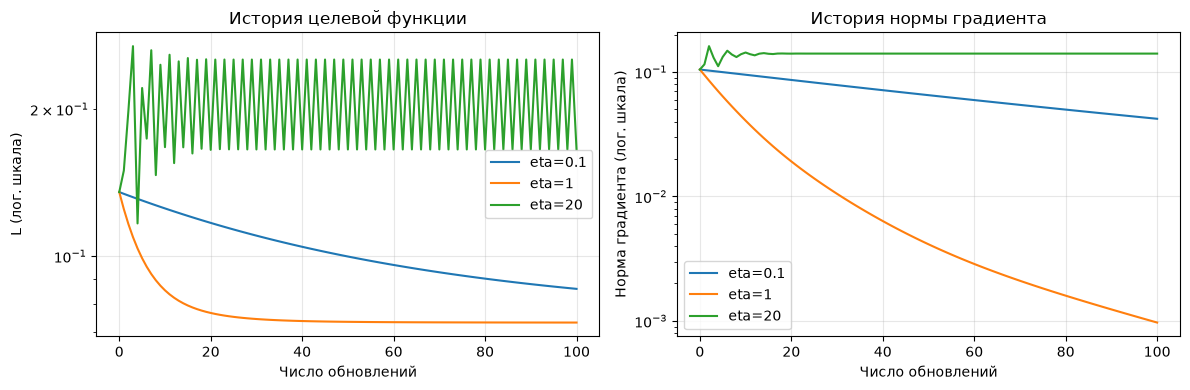

In [25]:
learning_rates=[.1,1.,20.]
iterations=100
optimization_runs={}
print("eta | начальное | после 100 | минимум | лучшая итерация | увеличений | max |Z|")
for eta in learning_rates:
    W,b=W_initial.copy(),b_initial.copy()
    losses=[];gradient_norms=[];max_z=0.
    for r in range(iterations):
        loss,gW,gb=objective_and_grad(W,b)
        losses.append(loss);gradient_norms.append(np.sqrt(np.sum(gW*gW)+gb@gb))
        max_z=max(max_z,float(np.max(np.abs(X_data@W+b))))
        W-=eta*gW;b-=eta*gb
    final_loss,gW,gb=objective_and_grad(W,b)
    max_z=max(max_z,float(np.max(np.abs(X_data@W+b))))
    final_norm=np.sqrt(np.sum(gW*gW)+gb@gb)
    full_losses=np.r_[losses,final_loss];full_norms=np.r_[gradient_norms,final_norm]
    increases=int(np.sum(np.diff(full_losses)>1e-12));best=int(np.argmin(full_losses))
    optimization_runs[eta]={"loss_history":np.array(losses),"gradient_history":np.array(gradient_norms),"full_losses":full_losses,"full_norms":full_norms,"final_W":W.copy(),"final_b":b.copy(),"best":best,"increases":increases,"max_z":max_z}
    print(f"{eta:g} | {losses[0]:.10f} | {final_loss:.10f} | {full_losses[best]:.10f} | {best} | {increases} | {max_z:.4f}")
    assert len(losses)==100 and len(gradient_norms)==100
    assert max_z<50
fig,axes=plt.subplots(1,2,figsize=(12,4))
for eta,run in optimization_runs.items():
    axes[0].semilogy(np.arange(101),run["full_losses"],label=f"eta={eta:g}")
    axes[1].semilogy(np.arange(101),run["full_norms"],label=f"eta={eta:g}")
axes[0].set(xlabel="Число обновлений",ylabel="L (лог. шкала)",title="История целевой функции")
axes[1].set(xlabel="Число обновлений",ylabel="Норма градиента (лог. шкала)",title="История нормы градиента")
for ax in axes:ax.grid(alpha=.3);ax.legend()
plt.tight_layout();plt.show()


## 10. Итоговая карта понятий


### Задание 10.1. Один язык для всех операторов

- **[Markdown]** Напишите связное резюме из 12–16 предложений, используя термины: *предел*, *производная*, *дифференциал*, *частная производная*, *градиент*, *производная по направлению*, *полная производная*, *якобиан*, *JVP*, *VJP*, *цепное правило*, *гессиан*, *след*, *матричный градиент*, *конечная разность*, *численная оптимизация*.
- **[Интерпретация]** Составьте таблицу минимум из восьми строк со столбцами: оператор, тип входа, тип выхода, размерность, какую чувствительность измеряет, как проверяется численно.
- **[Интерпретация]** Объясните на сквозной функции, где возникли суммы по индексам, где использовалось поэлементное умножение, где — матричное произведение и почему производная по $\mathbf W$ имеет размер $3\times2$.


#### Решение и интерпретация

Предел отношения приращений определяет производную скалярной функции как локальную скорость изменения.
Дифференциал использует эту скорость для линейного приближения небольшого изменения.
Для функции нескольких переменных частная производная описывает изменение по одной координате при фиксированных остальных.
Градиент объединяет эти частные производные в вектор, который становится коэффициентом полного дифференциала.
Производная по направлению получается скалярным произведением градиента и выбранного вектора движения.
Полная производная учитывает прямой и все косвенные пути влияния переменной на результат.
Когда выход векторный, якобиан собирает чувствительности всех выходных координат ко всем входным.
JVP переводит выбранное возмущение входа в локальное изменение всего выхода.
VJP, наоборот, переносит веса чувствительности скалярного результата с выходов на входы.
Цепное правило связывает эти операции при дифференцировании композиции, что в сквозной модели позволяет идти от потери через сигмоиду к весам и смещениям.
Гессиан описывает изменение градиента и помогает отличить минимум от седла и построить квадратичное приближение.
След позволяет компактно записать сумму квадратов элементов матрицы как $\operatorname{tr}(R^TR)$.
Матричный градиент имеет форму матрицы параметров и вычисляется суммированием вкладов наблюдений.
Конечная разность проверяет аналитические производные численно, но её ошибка зависит от шага, и она не доказывает существование производной.
Численная оптимизация использует проверенные градиенты для обновления параметров, а история потерь показывает влияние выбранного шага.

| Оператор | Тип входа | Тип выхода | Размерность выхода | Какая чувствительность | Численная проверка |
|---|---|---|---|---|---|
| Производная f′ | скаляр x, f: R→R | скаляр | 1 | изменение f при изменении x | две скалярные оценки |
| Частная производная | вектор x, f: Rⁿ→R | скаляр | 1 | изменение одной координаты | возмущение вдоль eᵢ |
| Градиент | вектор x, скалярная f | вектор | n×1 | все входные координаты | 2n оценок f |
| Дифференциал | x и Δx | скаляр, линейный по Δx | 1 | линейный прогноз изменения | сравнить с f(x+Δx)−f(x) |
| Производная по направлению | x и направление v | скаляр | 1 | изменение вдоль v | две оценки вдоль v |
| Полная производная | t и зависимые x(t), y(t) | скаляр | 1 | все пути влияния t | разность полной композиции |
| Якобиан | x∈Rⁿ, f: Rⁿ→Rᵐ | матрица | m×n | все выходы по всем входам | 2n векторных оценок |
| JVP | x и v∈Rⁿ | вектор | m×1 | выход вдоль входного v | две векторные оценки |
| VJP | x и u∈Rᵐ | вектор-строка | 1×n | взвешенные выходы по входам | градиент uᵀf(x) |
| Гессиан | x∈Rⁿ, скалярная f | матрица | n×n | изменение градиента | разности градиента по осям |
| HVP | x и v∈Rⁿ | вектор | n×1 | изменение градиента вдоль v | две оценки градиента |
| Матричный градиент | W∈Rᴰˣᴷ, скалярная L | матрица | D×K | каждый элемент параметров | разность каждого элемента |

В сквозной модели сумма по d формирует $Z_{nk}$, суммы по n,k дают потерю, а сумма по n — градиент смещения. Поэлементное умножение $G_H\odot H\odot(1-H)$ применяет локальную производную сигмоиды. Матричные произведения $XW$ и $X^TG_Z$ соответственно выполняют прямое преобразование и собирают градиент весов. Производная по W имеет размер 3×2, поскольку содержит одну чувствительность для каждого из шести независимых параметров W. Регуляризация добавляет λW той же формы.


## Что сдавать

Сдаётся заполненный студенческий ноутбук с сохранёнными результатами выполнения всех ячеек.

Перед отправкой проверьте:

- каждое ручное решение содержит формулу, подстановку и промежуточные действия;
- свободные и суммируемые индексы различаются корректно;
- размерности подписаны у градиентов, якобианов, JVP, VJP и гессианов;
- численные производные сравниваются с аналитическими по норме ошибки;
- стационарные точки классифицированы по кривизне, а не только по нулевому градиенту;
- матричные градиенты выведены и проверены по каждому элементу;
- максимальная ошибка проверки сквозной функции меньше $10^{-6}$;
- истории оптимизации начинаются из одной точки и содержат 100 значений;
- интерпретации ссылаются на конкретные числа и графики;
- все ячейки выполняются сверху вниз без ошибок.


## Краткая справка NumPy

```python
A @ B                              # матричное произведение
A * B                              # поэлементное произведение
np.einsum("ik,kj->ij", A, B)       # свёртка по индексам
np.outer(a, b)                     # внешнее произведение
np.trace(A)                        # след
np.linalg.norm(A, ord="fro")       # норма Фробениуса
np.linalg.eigvalsh(H)              # собственные значения симметричной матрицы
np.clip(z, -50.0, 50.0)            # ограничение перед exp
```

Все данные заданы внутри ноутбука. Интернет и дополнительные библиотеки не требуются.
